# Learning the $\omega$-limit partition: Bistable oscillations

This notebook walks through every stage of Algorithm 1 from *Learning Omega-Limit Partitions from
Approximate Koopman Invariants* on the `bistable_oscillations` example, using the `src_omega_partition` library
directly (the same code the `scripts/` pipeline runs). At each stage we sweep the relevant parameter
to show what it does, then fix it at the value used in the paper
(`configs/bistable_oscillations/build_partition.json`).

This planar system has two stable limit cycles (an inner and an outer one) separated by an unstable limit cycle. Every trajectory not on the unstable cycle converges to one of the two stable cycles, so the $\omega$-limit partition again has **two** cells and we expect $m = 2$ approximate invariant observables (the constant plus one non-trivial one). Because the attractors are cycles rather than points, the class anchors are the terminal snapshots of two reference trajectories, one on each stable cycle.

**Pipeline**

1. Dictionary $\Phi$ (Gaussian RBFs + polynomials) and the generalized eigenvalue problem
   $M w = \lambda N w$ that yields approximate invariant observables $f_j = \Phi w_j$ — parameters
   $\gamma$ (RBF precision), $\epsilon$ (eigenvalue tolerance).
2. Per-coordinate 1-D $k$-means on each $f_j$; the product of the scalar labels defines the *fine
   cells* — parameters $k_1, \ldots, k_r$.
3. Occupancy filter — parameter $\tau_{\mathrm{occ}}$.
4. Transition-based merging of fine cells — parameter $\tau_{\mathrm{tr}}$.
5. Value-based merging of the transition-merged nodes — parameter $\tau_{\mathrm{val}}$.
6. Optional robustness margin that drops points too close to a boundary — parameter
   $\tau_{\mathrm{robust}}$ (not in the paper).
7. Validation against labeled trajectories via class anchors.
8. Regional EDMD models on the final partition vs a vanilla EDMD model with the same
   dictionary (lift-once rollouts on two chosen initial conditions, one per limit cycle).
9. Sweep of the EDMD dictionary (RBF centers, $\gamma$, polynomial degree) with the partition fixed.

> **Remark (Parameter Tuning, from the paper).** We increase $\gamma$ until the generalized
> eigenvalue problem produces enough approximate invariant observables with eigenvalues below the
> prescribed tolerance $\epsilon$. We then choose the scalar clustering integers $k_1, \ldots, k_r$.
> In practice, the parity of $k_j$ can affect the quality of the initial fine partition. For the
> merging thresholds, we tune the transition threshold $\tau_{\mathrm{tr}}$ before using value-based
> merging. Specifically, we first set $\tau_{\mathrm{val}} = 0$ so that merging is driven only by
> observed transitions between fine cells. We then vary $\tau_{\mathrm{tr}}$. Smaller values of
> $\tau_{\mathrm{tr}}$ produce more aggressive merging and, in the extreme, may collapse the
> partition to a single cell. Starting from a small value, we gradually increase $\tau_{\mathrm{tr}}$
> until persistent cells appear and the resulting partition is approximately stationary on the data.
> After $\tau_{\mathrm{tr}}$ is fixed, the value-based threshold $\tau_{\mathrm{val}}$ can be used as
> a secondary refinement parameter. In our experiments, transition-based merging was often
> sufficient, and $\tau_{\mathrm{val}}$ was needed only for fine-tuning.

> Run this notebook in the `macbook_env` conda environment from the `notebooks/` folder
> (`jupyter lab notebooks/`). It only reads the committed datasets and writes nothing to `data/`.

## 0. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src_omega_partition").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src_omega_partition.paths import resolve
from src_omega_partition.dictionary import build_rbf_polynomial_dictionary
from src_omega_partition.invariants import (
    compute_approximate_invariant_observables,
    evaluate_invariant_embedding,
    select_invariant_modes,
)
from src_omega_partition.partition import (
    build_partition_inference,
    compute_relative_boundary_distances,
    fit_graph_merged_partition,
)
from src_omega_partition.anchors import (
    build_anchor_points,
    classify_embedding_with_anchors,
    print_anchor_assignments,
    print_classification_table,
)
from src_omega_partition.plotting import (
    plot_boundary_distance_histogram,
    plot_cell_weights,
    plot_inter_centroid_distances,
    plot_invariant_embedding_2d,
    plot_invariant_scalar_histograms,
    plot_misclassified_points,
    plot_state_partition_2d,
)

SYSTEM = "bistable_oscillations"
build_cfg = json.load(open(PROJECT_ROOT / f"configs/{SYSTEM}/build_partition.json"))
validate_cfg = json.load(open(PROJECT_ROOT / f"configs/{SYSTEM}/validate_partition.json"))

PAPER = {k: build_cfg[k] for k in (
    "gamma", "d_poly", "epsilon", "reg", "max_invariant_modes", "skip_first_mode",
    "scalar_cluster_count", "tau_occ", "tau_tr", "tau_val", "tau_robust", "random_state")}
pd.Series({k: str(v) for k, v in PAPER.items()}, name="paper value").to_frame()

,paper value
gamma,5.0
d_poly,3
epsilon,0.0001
reg,1e-10
max_invariant_modes,4
skip_first_mode,False
scalar_cluster_count,"[1, 4]"
tau_occ,0.0008
tau_tr,0.1
tau_val,0.006


### Data

Training snapshot pairs $(x_i, y_i)$ with $y_i = T(x_i)$ one sampling step later, the $k$-means RBF
centers computed by `generate_data.py`, and the labeled validation trajectories from
`generate_validation_data.py` (label = which attractor the trajectory eventually reached).

training snapshots: 25000, RBF centers: 500, validation snapshots: 150000, classes: 2


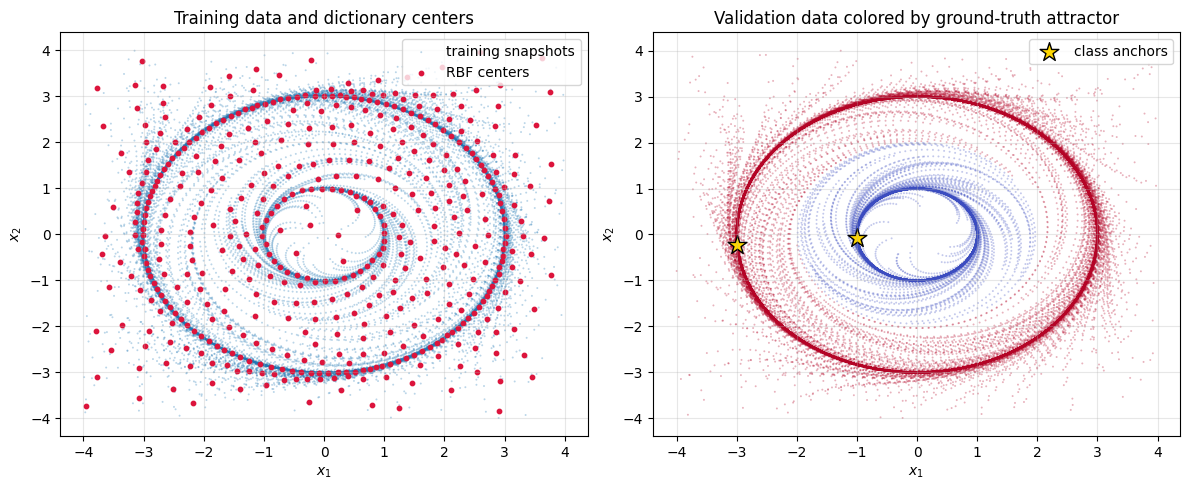

In [2]:
data = np.load(resolve(build_cfg["data_path"]))
X, Y, centers_global = data["X"], data["Y"], data["centers_global"]
n = X.shape[1]

val = np.load(resolve(validate_cfg["validation_data_path"]))
X_val, labels_val = val["X"], val["labels"].astype(np.int64)

anchors = build_anchor_points(
    {"target_equilibria": validate_cfg.get("target_equilibria"),
     "target_data_paths": validate_cfg.get("target_data_paths")},
    state_dim=n,
)
print(f"training snapshots: {X.shape[0]}, RBF centers: {centers_global.shape[0]}, "
      f"validation snapshots: {X_val.shape[0]}, classes: {anchors.shape[0]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X[:, 0], X[:, 1], s=2, alpha=0.3, edgecolors="none", label="training snapshots")
axes[0].scatter(centers_global[:, 0], centers_global[:, 1], s=10, c="crimson", label="RBF centers")
axes[0].set_title("Training data and dictionary centers")
axes[1].scatter(X_val[:, 0], X_val[:, 1], s=2, c=labels_val, cmap="coolwarm", alpha=0.3, edgecolors="none")
axes[1].scatter(anchors[:, 0], anchors[:, 1], s=200, marker="*", c="gold", edgecolors="black", label="class anchors")
axes[1].set_title("Validation data colored by ground-truth attractor")
for ax in axes:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### Helpers

Three thin wrappers around the library so every experiment below is a one-liner:

- `compute_embedding(gamma, ...)` builds the dictionary, solves the GEP and evaluates the invariant
  embedding on the training pairs, the validation states and the anchors (steps 1 of the pipeline).
- `fit_partition(emb, ...)` runs steps 2–6 (`fit_graph_merged_partition`) and returns both the raw
  result and the inference dict that `validate_partition.py` would load from `partition_output.npz`.
- `validate(emb, inference)` maps partition ids to classes through the anchors and scores the
  validation set (step 7). It returns `None` when validation is impossible because both anchors fall
  in the same cell or an anchor was dropped — that is what a collapsed partition looks like.

In [3]:
def compute_embedding(gamma, *, d_poly=PAPER["d_poly"], epsilon=PAPER["epsilon"], reg=PAPER["reg"],
                      max_modes=PAPER["max_invariant_modes"], skip_first_mode=PAPER["skip_first_mode"]):
    Phi = build_rbf_polynomial_dictionary(n, centers_global, gamma, d_poly)
    Phi_X, Phi_Y = Phi.evaluate(X), Phi.evaluate(Y)
    lam, vecs = compute_approximate_invariant_observables(Phi_X, Phi_Y, epsilon=epsilon, reg=reg)
    eigvals, coeffs = select_invariant_modes(lam, vecs, epsilon=epsilon, max_modes=max_modes,
                                             skip_first_mode=skip_first_mode)
    return dict(
        gamma=gamma, d_poly=d_poly, eigvals=eigvals, coeffs=coeffs,
        F_X=evaluate_invariant_embedding(Phi_X, coeffs),
        F_Y=evaluate_invariant_embedding(Phi_Y, coeffs),
        F_val=evaluate_invariant_embedding(Phi.evaluate(X_val), coeffs),
        F_anchors=evaluate_invariant_embedding(Phi.evaluate(anchors), coeffs),
    )


def fit_partition(emb, **overrides):
    params = dict(n_clusters=PAPER["scalar_cluster_count"], tau_occ=PAPER["tau_occ"], tau_tr=PAPER["tau_tr"],
                  tau_val=PAPER["tau_val"], tau_robust=0.0, random_state=PAPER["random_state"])
    params.update(overrides)
    result = fit_graph_merged_partition(emb["F_X"], emb["F_Y"], **params)
    inference = build_partition_inference(result, coeffs_inv=emb["coeffs"], centers_global=centers_global,
                                          gamma=emb["gamma"], d_poly=emb["d_poly"], n=n)
    return result, inference


def validate(emb, inference):
    try:
        return classify_embedding_with_anchors(F=emb["F_val"], F_anchors=emb["F_anchors"], anchors=anchors,
                                               gt_labels=labels_val, partition=inference)
    except ValueError as err:   # both anchors in one cell, or an anchor dropped
        return None


def summarize(result, res=None):
    row = dict(
        occupied=result["n_occupied_fine_cells"],
        retained=len(result["retained_cell_ids"]),
        after_tau_tr=len(result["transition_components"]),
        final=len(result["components"]),
        train_dropped=float(np.mean(result["final_labels_X"] < 0)),
    )
    if res is None:
        row.update(val_accuracy=np.nan, val_dropped=np.nan)
    else:
        row.update(val_accuracy=res.table_rows[1].rate, val_dropped=res.table_rows[2].rate)
    return row


def sweep(emb, name, values, **fixed):
    """Fit + validate for each value of one parameter; returns a DataFrame indexed by that parameter."""
    rows = []
    for v in values:
        result, inference = fit_partition(emb, **{name: v}, **fixed)
        rows.append(summarize(result, validate(emb, inference)))
    return pd.DataFrame(rows, index=pd.Index(values, name=name))


def scatter_cells(ax, labels, title, *, X_plot=None, s=3):
    """State-space scatter colored by cell label; dropped points (-1) in gray."""
    X_plot = X if X_plot is None else X_plot
    labels = np.asarray(labels)
    dropped = labels < 0
    ax.scatter(X_plot[dropped, 0], X_plot[dropped, 1], s=s, c="lightgray", edgecolors="none")
    ax.scatter(X_plot[~dropped, 0], X_plot[~dropped, 1], s=s, c=labels[~dropped], cmap="tab20",
               vmin=0, vmax=19, alpha=0.6, edgecolors="none")
    ax.set_title(title); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.grid(alpha=0.3)


pd.set_option("display.precision", 5)

## 1. Dictionary and approximate invariant observables ($\gamma$, $\epsilon$)

The dictionary is $\Phi(x) = [\exp(-\gamma\|x - c_i\|^2)]_i$ over the $k$-means centers, plus
monomials up to degree `d_poly` (the constant is included whenever `d_poly >= 0`). The generalized
eigenvalue problem
$$ (\Phi_Y - \Phi_X)^\top(\Phi_Y - \Phi_X)\, w = \lambda\, \Phi_Y^\top \Phi_Y\, w $$
measures how much $f = \Phi w$ changes along one step of the data; $\lambda \approx 0$ means
$f$ is approximately invariant. We keep the modes with $\lambda < \epsilon$ (at most
`max_invariant_modes` of them).

**How many is "enough"?** An observable that is invariant under the dynamics must be constant on
each $\omega$-limit component's basin, so with $m$ attractors the space of invariant observables has
dimension $m$. We therefore want *about* $m$ eigenvalues below $\epsilon$ — here $m = 2$
(the constant function plus 1 non-trivial mode) — with a visible gap above
them. Sweeping $\gamma$ shows the two failure modes on either side.

,n(lambda < epsilon),lambda_1,lambda_2,lambda_3,lambda_4
gamma,,,,,
0.500000,319,-2.42e-07,-2.31e-07,-2.23e-07,-2.1e-07
1.000000,204,-1.13e-07,-8.17e-08,-7.52e-08,-7.42e-08
2.000000,66,1.63e-12,2.48e-10,3.37e-08,3.98e-08
5.000000,2,-1.13e-13,3.42e-05,0.000922,0.000979
10.000000,1,-3.87e-12,0.000124,0.00108,0.00109
20.000000,1,9.54e-12,0.000407,0.00152,0.00165


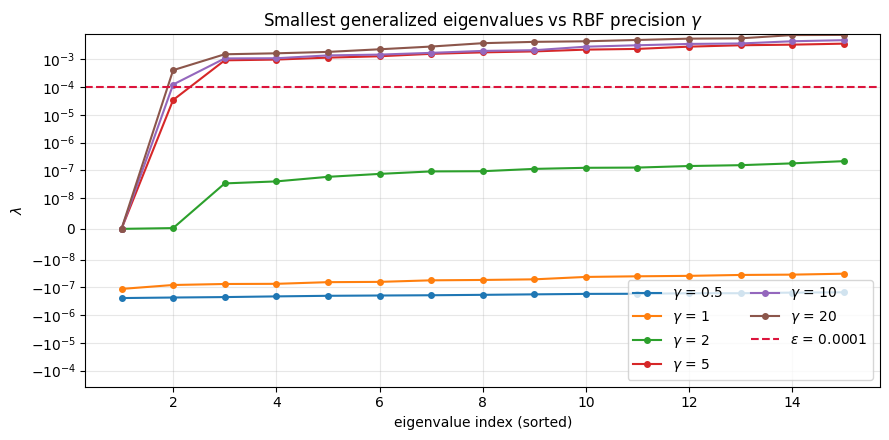

In [4]:
gamma_grid = [0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
epsilon = PAPER["epsilon"]

spectra = {}
for gamma in gamma_grid:
    Phi = build_rbf_polynomial_dictionary(n, centers_global, gamma, PAPER["d_poly"])
    lam, _ = compute_approximate_invariant_observables(Phi.evaluate(X), Phi.evaluate(Y), epsilon=np.inf, reg=PAPER["reg"])
    spectra[gamma] = np.sort(lam)

summary = pd.DataFrame({
    "n(lambda < epsilon)": [int(np.sum(spectra[g] < epsilon)) for g in gamma_grid],
    "lambda_1": [spectra[g][0] for g in gamma_grid],
    "lambda_2": [spectra[g][1] for g in gamma_grid],
    "lambda_3": [spectra[g][2] for g in gamma_grid],
    "lambda_4": [spectra[g][3] for g in gamma_grid],
}, index=pd.Index(gamma_grid, name="gamma"))
display(summary.style.format({c: "{:.3g}" for c in summary.columns if c.startswith("lambda")}))

fig, ax = plt.subplots(figsize=(9, 4.5))
n_show = 15
for gamma in gamma_grid:
    ax.plot(np.arange(1, n_show + 1), spectra[gamma][:n_show], "o-", ms=4, label=rf"$\gamma$ = {gamma:g}")
ax.axhline(epsilon, color="crimson", ls="--", label=rf"$\epsilon$ = {epsilon:g}")
ax.set_yscale("symlog", linthresh=1e-8)
ax.set_xlabel("eigenvalue index (sorted)"); ax.set_ylabel(r"$\lambda$")
ax.set_title("Smallest generalized eigenvalues vs RBF precision $\\gamma$")
ax.grid(alpha=0.3); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

Two regimes are visible:

- **$\gamma$ too small** (wide bumps): hundreds of eigenvalues sit below $\epsilon$, many of them
  slightly *negative*. Wide RBFs are nearly linearly dependent, so $\Phi_Y^\top\Phi_Y$ is close to
  singular and the GEP returns a large numerical null space, not genuine invariants. Any
  eigenvector from this pile is noise.
- **$\gamma$ too large** (narrow bumps): each RBF sees only a few snapshots, the observables can no
  longer be nearly constant along trajectories, and only the exact constant survives below
  $\epsilon$.

The paper value $\gamma = 5$
is the smallest value on the grid where exactly $m = 2$ eigenvalues fall below
$\epsilon$ with a clear gap to the third. That is the "increase $\gamma$ until enough" rule of the
remark, with "enough" read as "as many as there are attractors, and no spurious extras".

gamma = 5.0: r = 2 invariant modes, eigenvalues [-1.13177040e-13  3.41758047e-05]  (6.7s)


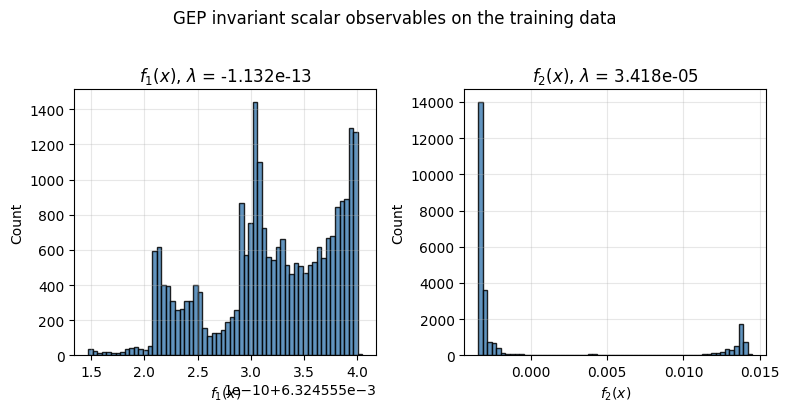

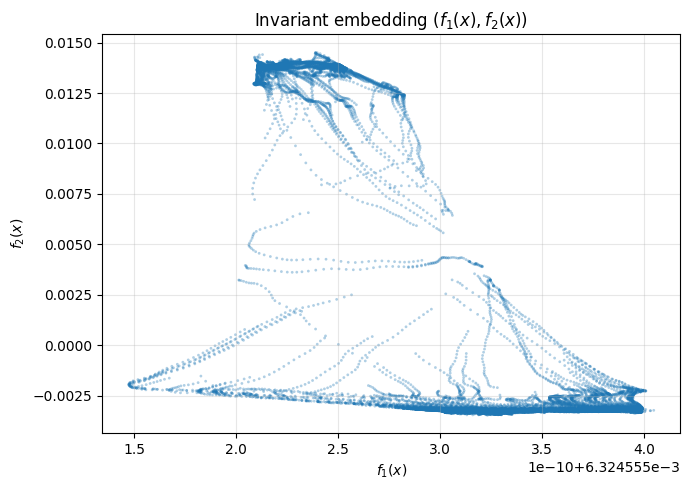

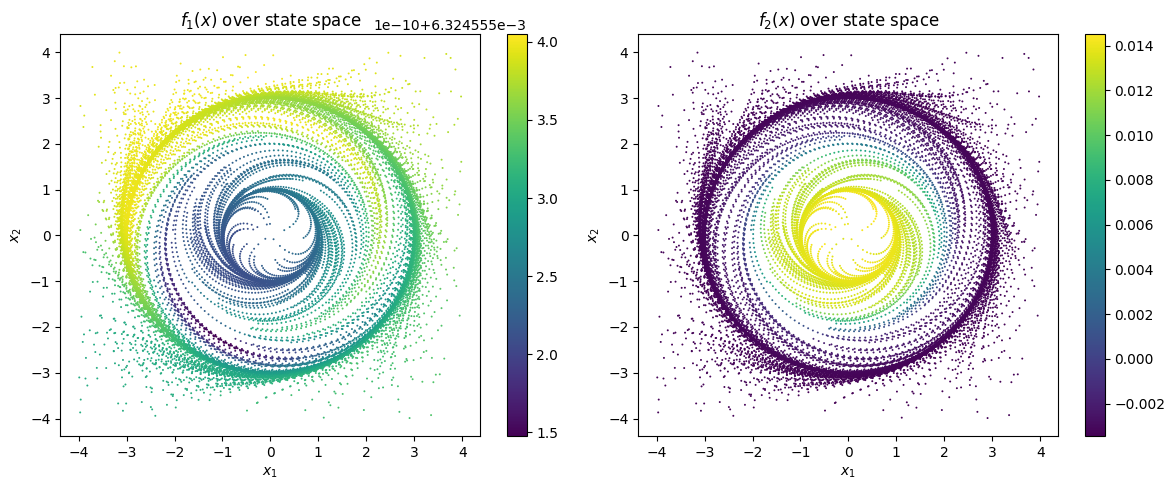

In [5]:
t0 = time.time()
emb = compute_embedding(PAPER["gamma"])
print(f"gamma = {PAPER['gamma']}: r = {emb['eigvals'].size} invariant modes, eigenvalues {emb['eigvals']}  ({time.time() - t0:.1f}s)")

_ = plot_invariant_scalar_histograms(emb["F_X"], emb["eigvals"], title="GEP invariant scalar observables on the training data")
_ = plot_invariant_embedding_2d(emb["F_X"], title=r"Invariant embedding $(f_1(x), f_2(x))$")

fig, axes = plt.subplots(1, emb["F_X"].shape[1], figsize=(6 * emb["F_X"].shape[1], 5), squeeze=False)
for j, ax in enumerate(axes[0]):
    sc = ax.scatter(X[:, 0], X[:, 1], s=2, c=emb["F_X"][:, j], cmap="viridis", edgecolors="none")
    fig.colorbar(sc, ax=ax); ax.set_title(rf"$f_{j + 1}(x)$ over state space"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.tight_layout(); plt.show()

The first mode is the constant function ($\lambda_1 \approx 10^{-16}$, a spike in the histogram),
which is why its cluster count must be `1` in `scalar_cluster_count`. The second mode is the
interesting one: it is nearly piecewise constant in state space, taking one plateau value on each
basin, with the transition region concentrated along the boundary between them. Everything that
follows is about turning that plateau structure into a labeled partition.

## 2. Scalar clustering and fine cells ($k_1, \ldots, k_r$)

Each coordinate $f_j(x)$ is clustered independently with 1-D $k$-means into $k_j$ groups; the
tuple of scalar labels is the *fine cell* of $x$. We keep $k_1 = 1$ for the constant mode and sweep
$k_2$. The plots show the fine cells **before any merging** (each color is one fine cell); the
table shows how each choice fares after the paper's merge thresholds are applied.

The same parity effect appears here: with $k_2 = 3$ the middle cluster is a thin ring around the unstable limit cycle, straddling the boundary between the two basins, while an even $k_2$ puts a cluster boundary on the unstable cycle. The difference from Duffing is what happens next. The paper thresholds ($\tau_{\mathrm{tr}} = 0.1$) disable transition-based merging, so the ring is *not* used as a bridge — it survives as a third cell that no anchor maps to, and its validation points count as dropped (~0.5%). For $k_2 \ge 6$ the fine cells become so narrow in $f_2$ that value-based merging at $\tau_{\mathrm{val}} = 0.006$ chains all of them together and the partition collapses to one cell. Either way the choice of $k_j$ interacts with the thresholds and has to be checked visually.

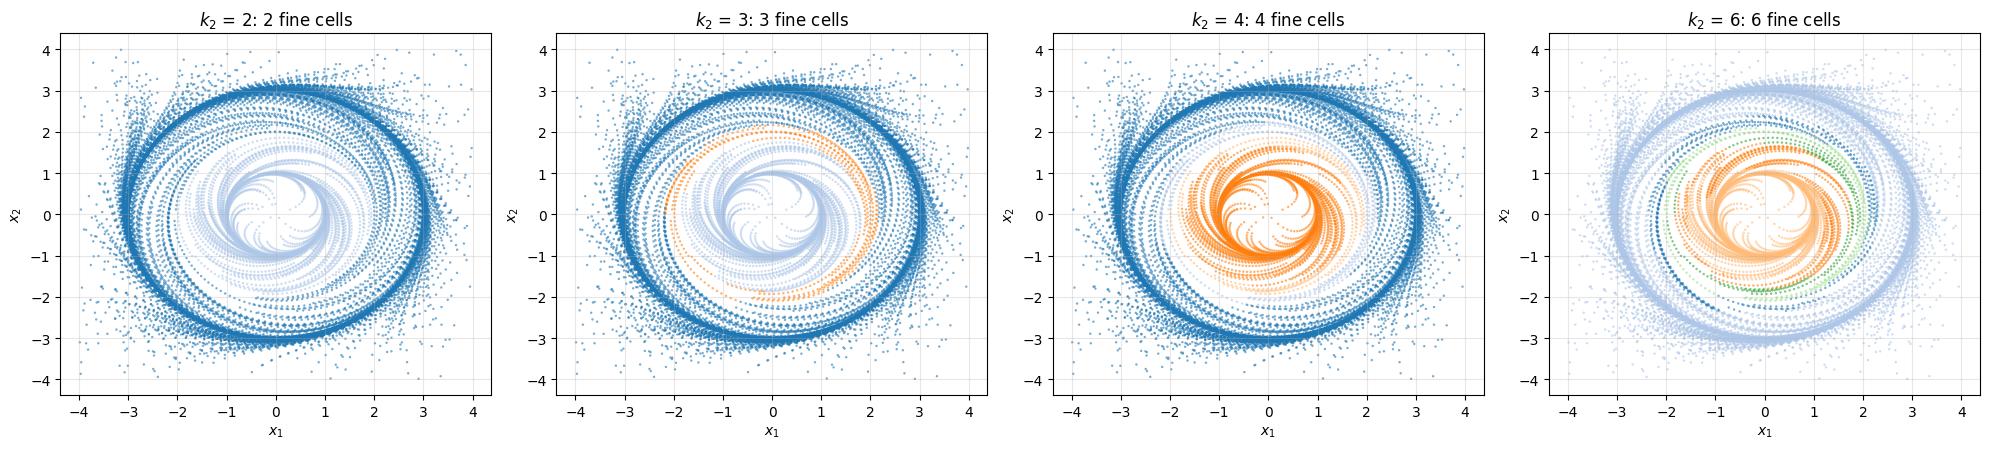

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
k_2,,,,,,,
2,2,2,2,2,0.0,0.99914,0.00000
3,3,3,3,3,0.0,1.00000,0.00507
4,4,4,4,2,0.0,0.99900,0.00000
5,5,5,5,2,0.0,0.99881,0.00000
6,6,6,6,1,0.0,NaN,NaN
8,8,8,8,1,0.0,NaN,NaN


In [6]:
k_grid = [2, 3, 4, 5, 6, 8]
k_show = [2, 3, 4, 6]

fig, axes = plt.subplots(1, len(k_show), figsize=(5 * len(k_show), 4.6))
for ax, k in zip(axes, k_show):
    result, _ = fit_partition(emb, n_clusters=[1, k])
    scatter_cells(ax, result["cell_ids_X"], rf"$k_2$ = {k}: {result['n_occupied_fine_cells']} fine cells")
plt.tight_layout(); plt.show()

table_k = sweep(emb, "n_clusters", [[1, k] for k in k_grid])
table_k.index = pd.Index(k_grid, name="k_2")
table_k

Per row: number of occupied fine cells, cells surviving the occupancy filter, nodes after the
transition merge, final cells, fraction of training points dropped, and validation accuracy on
un-dropped points / fraction of validation points dropped (NaN = validation impossible because
the partition collapsed to one cell).

## 3. Occupancy filter ($\tau_{\mathrm{occ}}$)

Fine cells with empirical weight $|C_\alpha| / N < \tau_{\mathrm{occ}}$ are dropped before the
transition graph is built. The transition merge compares an empirical *probability*
$p_{ab} = n_{ab} / n_a$ with $\tau_{\mathrm{tr}}$, so a cell with only a handful of points can
produce a large $p_{ab}$ from one or two stray transitions and bridge two basins;
$\tau_{\mathrm{occ}}$ is a minimum-count guard on that denominator
(see `plotting/tau_occ_sensitivity.md`).

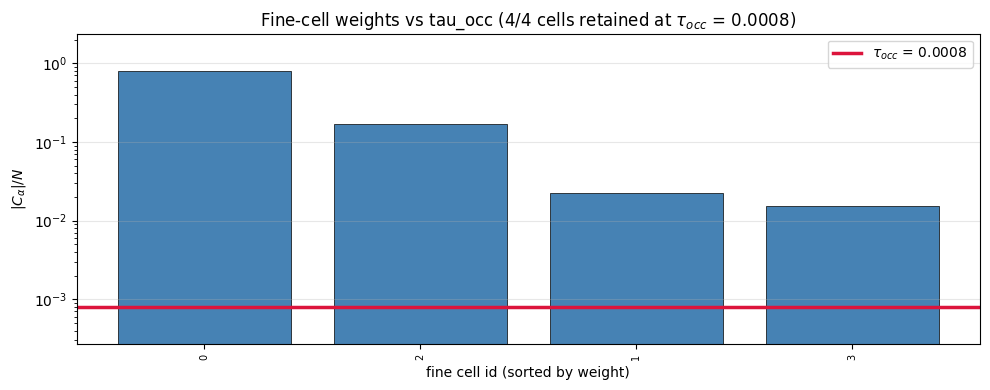

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_occ,,,,,,,
0.0000,4,4,4,2,0.00000,0.99900,0.00000
0.0008,4,4,4,2,0.00000,0.99900,0.00000
0.0050,4,4,4,2,0.00000,0.99900,0.00000
0.0200,4,3,3,2,0.01512,0.99903,0.00357
0.0500,4,2,2,2,0.03752,1.00000,0.00783


In [7]:
result_paper_k, _ = fit_partition(emb)
_ = plot_cell_weights(result_paper_k["cell_weights"], PAPER["tau_occ"])

table_occ = sweep(emb, "tau_occ", [0.0, 0.0008, 0.005, 0.02, 0.05])
table_occ

With the paper's $k_2$ every fine cell is well populated, so on the grid above
$\tau_{\mathrm{occ}}$ either does nothing or, once raised well above its paper value, removes
cells that *should* be kept (their points then count as dropped). It becomes important with larger
$k_j$ or higher-dimensional embeddings, where thin cells along the boundary appear — the paper value
is a safety margin for that situation rather than an active constraint here. The next cell makes
that situation happen on purpose.

### When $\tau_{\mathrm{occ}}$ is essential

To see the guard in action we go back to the configuration this example used before the current one: $\gamma = 1$ with four invariant modes and $(k_1, \ldots, k_4) = (1, 4, 4, 2)$, i.e. 32 fine cells on 25 000 snapshots, several of them holding only a handful of points. (Recall from section 1 that at $\gamma = 1$ the spectrum has hundreds of near-zero eigenvalues; the first four are still usable, but the fine partition they induce is far more fragmented than the two-mode one.) The thresholds are that configuration's $\tau_{\mathrm{tr}} = 0.1$, $\tau_{\mathrm{val}} = 7 \times 10^{-6}$; see `plotting/tau_occ_sensitivity.md` for the full ablation.

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_occ,,,,,,,
0.0000,32,32,1,1,0.00000,NaN,NaN
0.0001,32,31,1,1,0.00008,NaN,NaN
0.0004,32,29,1,1,0.00040,NaN,NaN
0.0008,32,27,2,2,0.00164,0.99849,0.00052
0.0020,32,23,4,2,0.00756,0.99872,0.00168
0.0100,32,11,5,2,0.07720,0.99951,0.01515


smallest usable tau_occ on the grid: 0.0008; it removes 5 of 32 fine cells


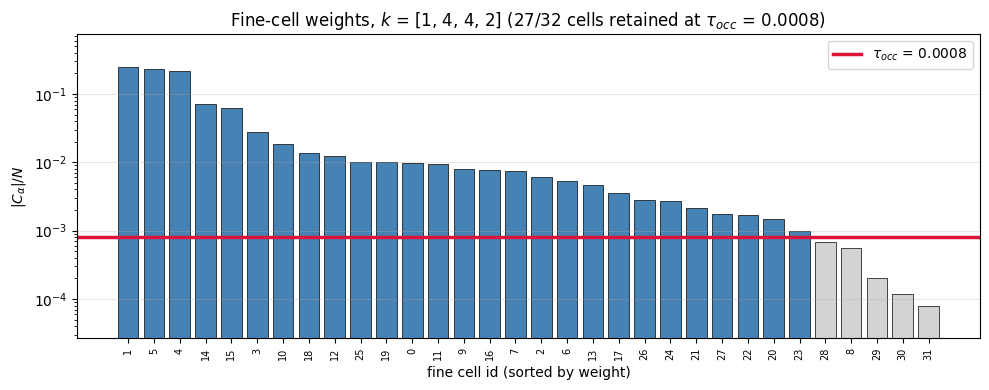

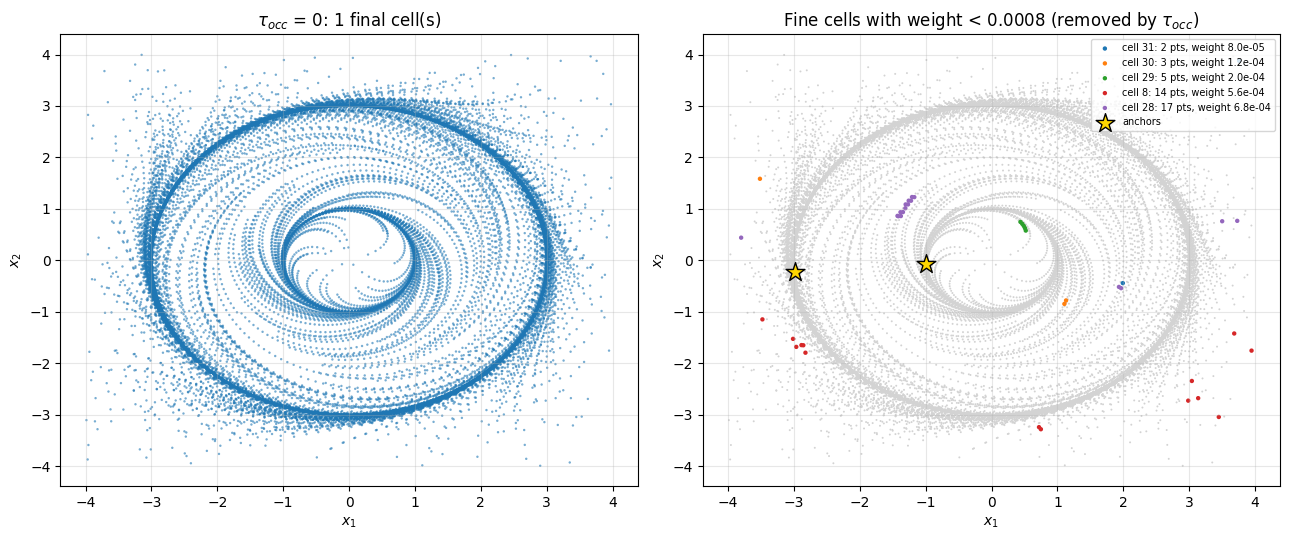

In [8]:
OCC_DEMO = dict(n_clusters=[1, 4, 4, 2], tau_tr=0.1, tau_val=7e-6)
tau_occ_demo = [0.0, 0.0001, 0.0004, 0.0008, 0.002, 0.01]

emb_demo = compute_embedding(1.0, max_modes=4)   # gamma = 1, four modes: the previous committed configuration
table_occ_demo = sweep(emb_demo, "tau_occ", tau_occ_demo, **OCC_DEMO)
display(table_occ_demo)

# smallest tau_occ on the grid that yields a usable two-cell partition
usable = table_occ_demo.index[(table_occ_demo["final"] == 2) & table_occ_demo["val_accuracy"].notna()]
TAU_OK = float(usable[0])

result_occ0, _ = fit_partition(emb_demo, tau_occ=0.0, **OCC_DEMO)
weights = result_occ0["cell_weights"]
thin_cells = sorted((cid for cid, w in weights.items() if w < TAU_OK), key=lambda cid: weights[cid])
print(f"smallest usable tau_occ on the grid: {TAU_OK:g}; it removes {len(thin_cells)} of {len(weights)} fine cells")

_ = plot_cell_weights(weights, TAU_OK, title=rf"Fine-cell weights, $k$ = {OCC_DEMO['n_clusters']}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
scatter_cells(axes[0], result_occ0["final_labels_X"],
              rf"$\tau_{{occ}}$ = 0: {len(result_occ0['components'])} final cell(s)")
axes[1].scatter(X[:, 0], X[:, 1], s=2, c="lightgray", edgecolors="none")
for cid in thin_cells:
    mask = result_occ0["cell_ids_X"] == cid
    axes[1].scatter(X[mask, 0], X[mask, 1], s=10, edgecolors="none",
                    label=f"cell {cid}: {int(mask.sum())} pts, weight {weights[cid]:.1e}")
axes[1].scatter(anchors[:, 0], anchors[:, 1], s=200, marker="*", c="gold", edgecolors="black", zorder=5, label="anchors")
axes[1].set_title(rf"Fine cells with weight < {TAU_OK:g} (removed by $\tau_{{occ}}$)")
axes[1].set_xlabel("$x_1$"); axes[1].set_ylabel("$x_2$"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

For every $\tau_{\mathrm{occ}} < 8 \times 10^{-4}$ the two limit cycles collapse into one component and validation fails. Five fine cells lie below the paper value; the two that matter (17 and 3 points) contain points on both sides of the unstable cycle at $r = 2$, so two or three transitions are enough to give them $p_{ab} > 0.1$ into both basins and they act as bridges. The paper value $8 \times 10^{-4}$ (a minimum of 20 points per cell) removes them and the partition is recovered at 99.85% accuracy with 0.05% dropped; raising it further trades accuracy for dropped points as genuine cells go. This is why $\tau_{\mathrm{occ}}$ should be thought of as a minimum-count guard on the denominator of $p_{ab}$: an edge needs at least $\tau_{\mathrm{occ}} \cdot N \cdot \tau_{\mathrm{tr}}$ observed transitions.

## 4. Transition-based merging ($\tau_{\mathrm{tr}}$, with $\tau_{\mathrm{val}} = 0$)

Following the remark we first switch value-based merging off ($\tau_{\mathrm{val}} = 0$) and
sweep $\tau_{\mathrm{tr}}$. Two retained fine cells $a, b$ are joined when
$\max(p_{ab}, p_{ba}) \ge \tau_{\mathrm{tr}}$, and the final cells are the connected components
of that graph. The first plot shows the pairwise transition scores against the threshold; the
second shows how the number of final cells and the validation accuracy move with it.

inter-cell transition scores max(p_ab, p_ba), descending: [0.05291 0.04286 0.00179 0.      0.      0.     ]


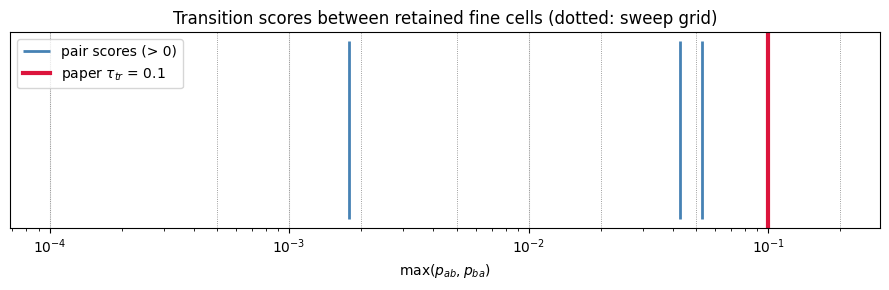

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_tr,,,,,,,
0.0001,4,4,1,1,0.0,NaN,NaN
0.0005,4,4,1,1,0.0,NaN,NaN
0.0010,4,4,1,1,0.0,NaN,NaN
0.0020,4,4,2,2,0.0,0.99900,0.00000
0.0050,4,4,2,2,0.0,0.99900,0.00000
0.0100,4,4,2,2,0.0,0.99900,0.00000
0.0200,4,4,2,2,0.0,0.99900,0.00000
0.0500,4,4,3,3,0.0,0.99997,0.00426
0.1000,4,4,4,4,0.0,1.00000,0.00783


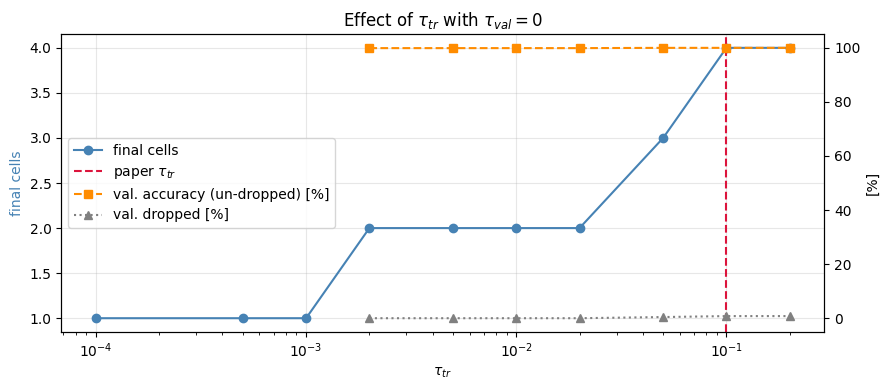

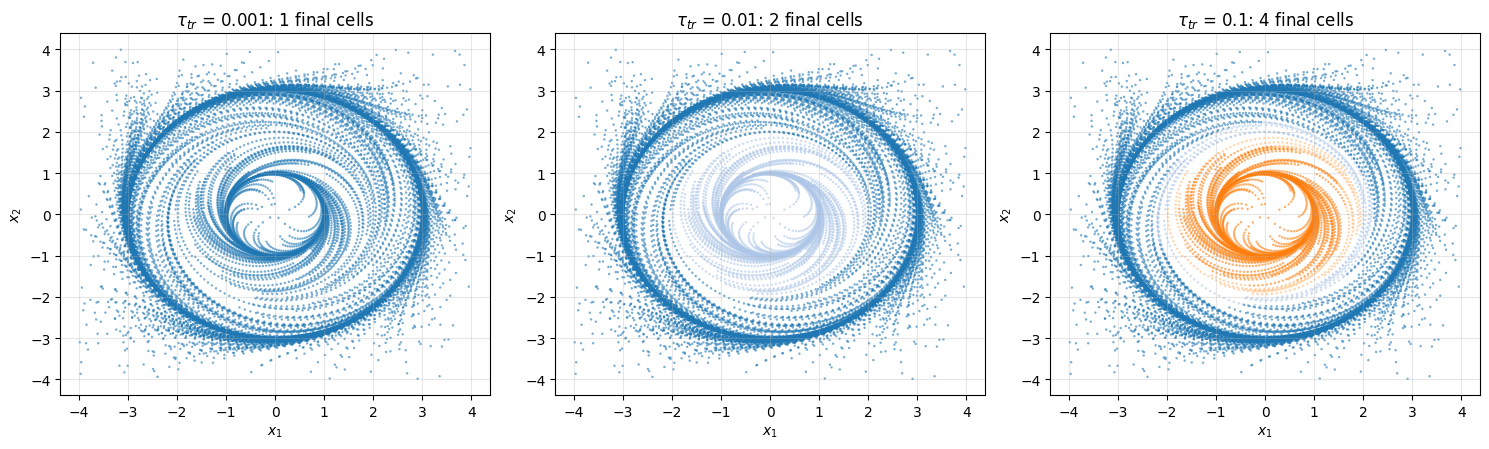

In [9]:
tau_tr_grid = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2]

result_tr0, _ = fit_partition(emb, tau_val=0.0)
scores = np.sort(np.asarray(result_tr0["transition_pair_scores"]))[::-1]
print("inter-cell transition scores max(p_ab, p_ba), descending:", np.round(scores, 5))

fig, ax = plt.subplots(figsize=(9, 3))
ax.vlines(scores[scores > 0], 0, 1, colors="steelblue", lw=2, label="pair scores (> 0)")
for t in tau_tr_grid:
    ax.axvline(t, color="gray", lw=0.6, ls=":")
ax.axvline(PAPER["tau_tr"], color="crimson", lw=3, label=rf"paper $\tau_{{tr}}$ = {PAPER['tau_tr']}")
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel(r"$\max(p_{ab}, p_{ba})$")
ax.set_title("Transition scores between retained fine cells (dotted: sweep grid)")
ax.legend(loc="upper left"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

table_tr = sweep(emb, "tau_tr", tau_tr_grid, tau_val=0.0)
display(table_tr)

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(table_tr.index, table_tr["final"], "o-", color="steelblue", label="final cells")
ax1.set_xscale("log"); ax1.set_xlabel(r"$\tau_{tr}$"); ax1.set_ylabel("final cells", color="steelblue")
ax1.axvline(PAPER["tau_tr"], color="crimson", ls="--", label=r"paper $\tau_{tr}$")
ax2 = ax1.twinx()
ax2.plot(table_tr.index, 100 * table_tr["val_accuracy"], "s--", color="darkorange", label="val. accuracy (un-dropped) [%]")
ax2.plot(table_tr.index, 100 * table_tr["val_dropped"], "^:", color="gray", label="val. dropped [%]")
ax2.set_ylabel("[%]")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center left"); ax1.grid(alpha=0.3)
ax1.set_title(r"Effect of $\tau_{tr}$ with $\tau_{val} = 0$")
plt.tight_layout(); plt.show()

tau_tr_show = [0.001, 0.01, 0.1]
fig, axes = plt.subplots(1, len(tau_tr_show), figsize=(5 * len(tau_tr_show), 4.6))
for ax, t in zip(axes, tau_tr_show):
    result, _ = fit_partition(emb, tau_tr=t, tau_val=0.0)
    scatter_cells(ax, result["final_labels_X"], rf"$\tau_{{tr}}$ = {t:g}: {len(result['components'])} final cells")
plt.tight_layout(); plt.show()

With $\tau_{\mathrm{val}} = 0$, transition-based merging alone recovers the two limit cycles for $\tau_{\mathrm{tr}}$ anywhere in roughly $[0.002, 0.02]$ — a wide, stationary plateau. Below it the partition collapses; above $0.05$ the two inner fine cells stop merging and the partition has three or four cells. The paper configuration uses $\tau_{\mathrm{tr}} = 0.1$, i.e. it sits *above* the plateau where no transition merge happens, and relies on $\tau_{\mathrm{val}}$ for the merge (next section). Both routes give the same two-cell partition.

## 5. Value-based merging ($\tau_{\mathrm{val}}$)

With $\tau_{\mathrm{tr}}$ fixed at its paper value, the transition-merged nodes are compared by
the distance between their centroids in embedding space, $\|m_\alpha - m_\beta\|_2$, and joined
when it is below $\tau_{\mathrm{val}}$.

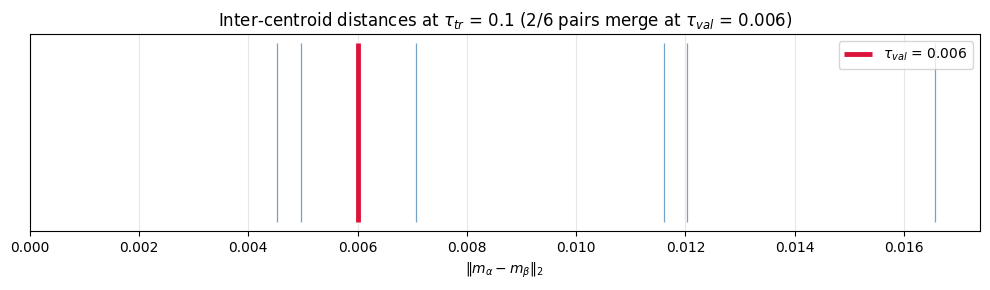

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_val,,,,,,,
0.000,4,4,4,4,0.0,1.000,0.00783
0.002,4,4,4,4,0.0,1.000,0.00783
0.004,4,4,4,4,0.0,1.000,0.00783
0.006,4,4,4,2,0.0,0.999,0.00000
0.010,4,4,4,1,0.0,NaN,NaN
0.020,4,4,4,1,0.0,NaN,NaN


In [10]:
result_paper_tr, _ = fit_partition(emb, tau_val=0.0)
_ = plot_inter_centroid_distances(result_paper_tr["centroid_pair_distances"], PAPER["tau_val"],
                                  title=rf"Inter-centroid distances at $\tau_{{tr}}$ = {PAPER['tau_tr']}")

table_val = sweep(emb, "tau_val", [0.0, 0.002, 0.004, 0.006, 0.01, 0.02])
table_val

With $\tau_{\mathrm{tr}} = 0.1$ there are four transition-merged nodes and six centroid pairs. The two smallest centroid distances (~0.0045 and ~0.0050) are the pairs of fine cells that belong to the same limit cycle; $\tau_{\mathrm{val}} = 0.006$ merges exactly those, while $\tau_{\mathrm{val}} \ge 0.01$ also merges across the unstable cycle and collapses the partition. This is $\tau_{\mathrm{val}}$ in its intended role as a fine-tuning parameter.

## 6. Final partition with the paper parameters

Putting the choices together (no robustness margin yet).

occupied         4.0
retained         4.0
after_tau_tr     4.0
final            2.0
train_dropped    0.0
merge edges: 0 transition, 2 value


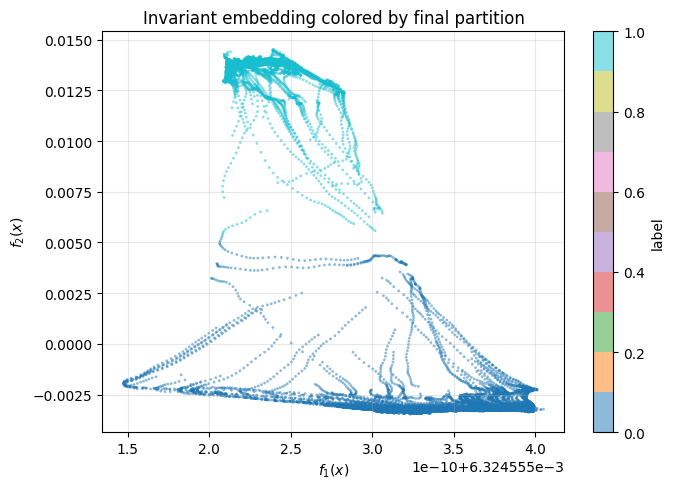

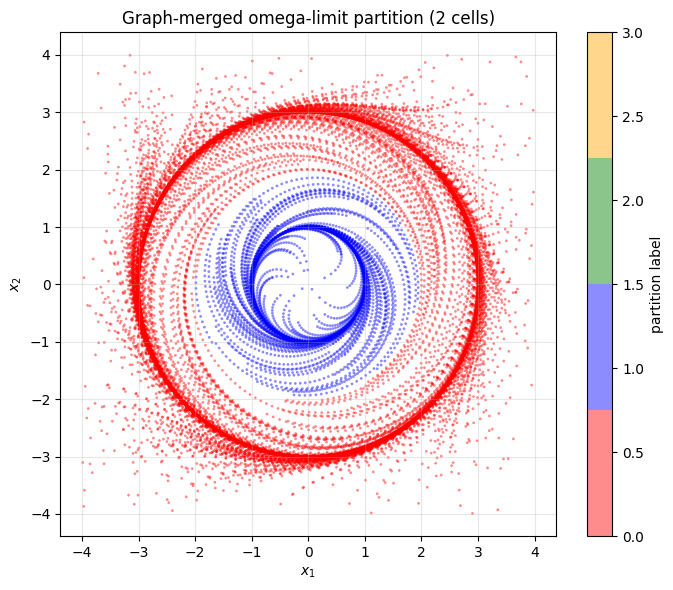

In [11]:
result, inference = fit_partition(emb)
print(pd.Series({k: v for k, v in summarize(result).items() if not k.startswith("val_")}).to_string())
print("merge edges:", len(result["merge_edges_transition"]), "transition,", len(result["merge_edges_value"]), "value")

_ = plot_invariant_embedding_2d(emb["F_X"], labels=result["final_labels_X"], title="Invariant embedding colored by final partition")
_ = plot_state_partition_2d(X, result["final_labels_X"], title=f"Graph-merged omega-limit partition ({len(result['components'])} cells)")

## 7. Validation against labeled trajectories

A partition label is just an integer; to score it we need to know which label corresponds to which
attractor. Each class anchor is classified by the partition, which gives the map
partition id $\to$ class, and every validation snapshot is then scored by whether it lands in the
same partition cell as its trajectory's eventual attractor.

For this system the anchors come from `target_data_paths` in `configs/bistable_oscillations/validate_partition.json`: the last snapshot of a reference trajectory on each stable limit cycle.

Anchor assignments:
  class 0: state=(-0.997003, -0.0773575) -> partition 1
  class 1: state=(-2.99101, -0.232073) -> partition 0
Predicted partition labels (excluding dropped): [0, 1]

+----------------------+---------------------+----------------------------+---------+--------+--------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate   |
+======================+=====================+============================+=========+========+========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 149850  | 150000 | 99.90% |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 149850  | 150000 | 99.90% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 0       | 150000 | 0.00%  |
+----------------------+---------------------+----------------------------+---------+--------+--------+


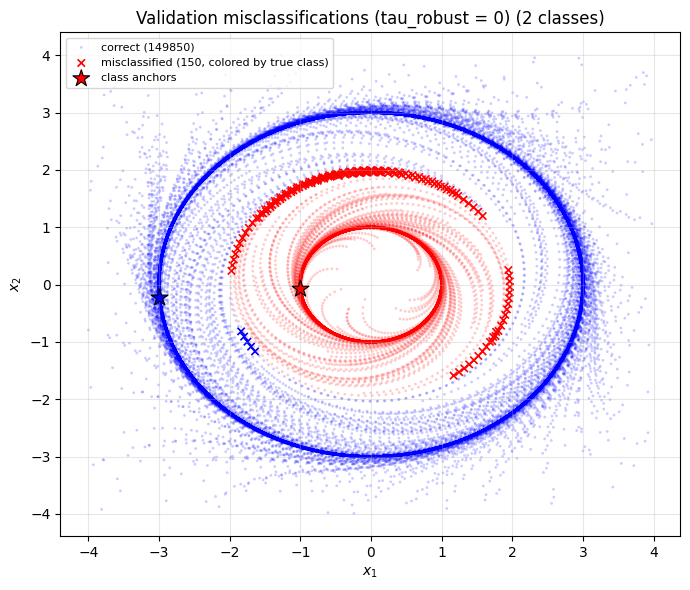

In [12]:
res = validate(emb, inference)
print_anchor_assignments(res.anchors, res.anchor_partitions, pred_raw=res.pred_raw)
print()
print_classification_table(res.table_rows)

_ = plot_misclassified_points(X_val, res.gt_labels, res.pred_mapped, anchors=res.anchors,
                              title="Validation misclassifications (tau_robust = 0)")

The errors, when there are any, sit along the boundary between the basins (and near the edge of
the sampled domain where the RBF dictionary runs out of centers). We can quantify "near the
boundary" in the embedding: for each coordinate $f_j$, the distance from $f_j(x)$ to the nearest
cluster boundary *at which the final label changes*, divided by the length of the merged region
along $f_j$; then the minimum over $j$. Misclassified samples should have a small value of this
relative distance, correctly classified ones should not.

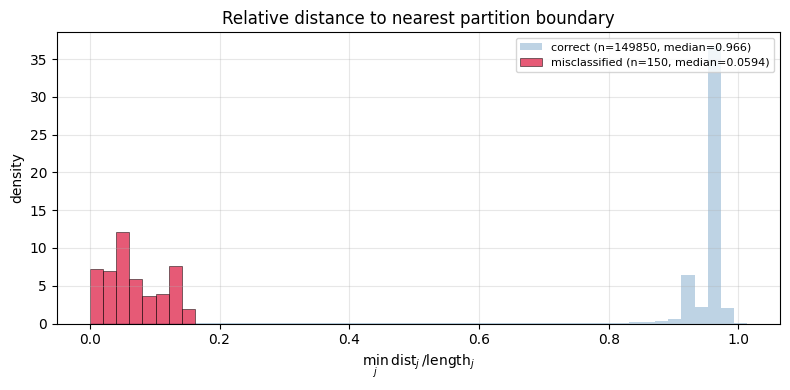

misclassified: n=    150  median=0.0594  frac < 0.05 = 0.420
      correct: n= 149850  median=0.9659  frac < 0.05 = 0.000


In [13]:
rel_dist, _ = compute_relative_boundary_distances(emb["F_val"], inference)
misclassified = (res.pred_mapped >= 0) & (res.pred_mapped != res.gt_labels)
_ = plot_boundary_distance_histogram(rel_dist, misclassified, baseline_mask=res.correct_mask)

for name, mask in (("misclassified", misclassified), ("correct", res.correct_mask)):
    vals = rel_dist[mask & np.isfinite(rel_dist)]
    if vals.size:
        print(f"{name:>13}: n={vals.size:7d}  median={np.median(vals):.4f}  frac < 0.05 = {np.mean(vals < 0.05):.3f}")
    else:
        print(f"{name:>13}: n=0")

### Robustness margin ($\tau_{\mathrm{robust}}$)

Because the errors are concentrated near the boundary, dropping every point whose relative boundary
distance is below $\tau_{\mathrm{robust}}$ trades a small fraction of *dropped* predictions for a
higher accuracy on the points that are classified. The margin is stored with the partition and
applied identically to training and validation data.

,occupied,retained,after_tau_tr,final,train_dropped,val_accuracy,val_dropped
tau_robust,,,,,,,
0.00,4,4,4,2,0.00000,0.99900,0.00000
0.02,4,4,4,2,0.00016,0.99915,0.00030
0.05,4,4,4,2,0.00056,0.99942,0.00077
0.10,4,4,4,2,0.00132,0.99971,0.00133
0.20,4,4,4,2,0.00844,1.00000,0.00231
0.30,4,4,4,2,0.01260,1.00000,0.00299


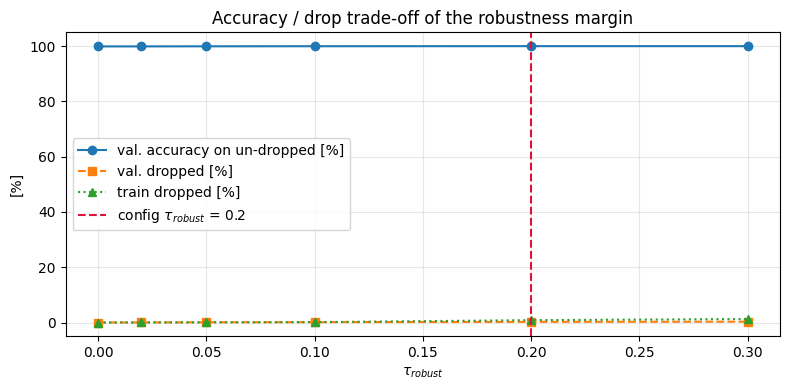

In [14]:
tau_robust_grid = [0.0, 0.02, 0.05, 0.1, 0.2, 0.3]
table_robust = sweep(emb, "tau_robust", tau_robust_grid)
display(table_robust)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tau_robust_grid, 100 * table_robust["val_accuracy"], "o-", label="val. accuracy on un-dropped [%]")
ax.plot(tau_robust_grid, 100 * table_robust["val_dropped"], "s--", label="val. dropped [%]")
ax.plot(tau_robust_grid, 100 * table_robust["train_dropped"], "^:", label="train dropped [%]")
ax.axvline(PAPER["tau_robust"], color="crimson", ls="--", label=rf"config $\tau_{{robust}}$ = {PAPER['tau_robust']}")
ax.set_xlabel(r"$\tau_{robust}$"); ax.set_ylabel("[%]"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Accuracy / drop trade-off of the robustness margin")
plt.tight_layout(); plt.show()

tau_robust = 0.2
+----------------------+---------------------+----------------------------+---------+--------+---------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate    |
+======================+=====================+============================+=========+========+=========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 149653  | 150000 | 99.77%  |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 149653  | 149653 | 100.00% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 347     | 150000 | 0.23%   |
+----------------------+---------------------+----------------------------+---------+--------+---------+


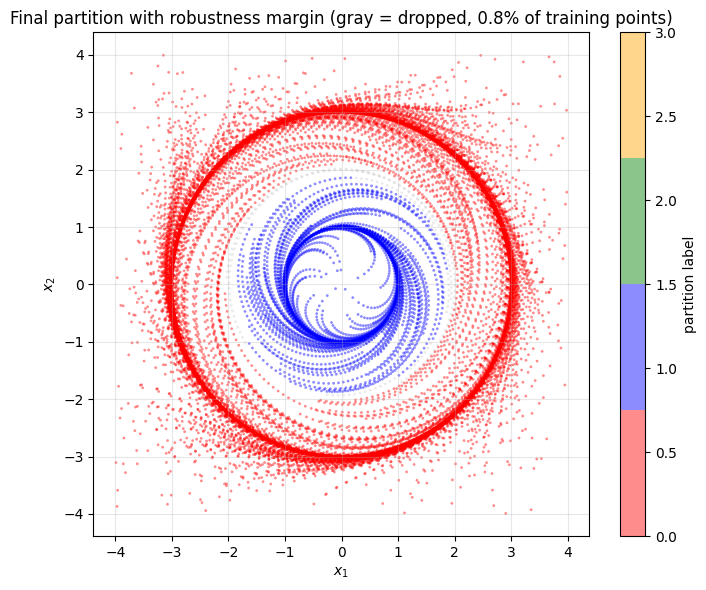

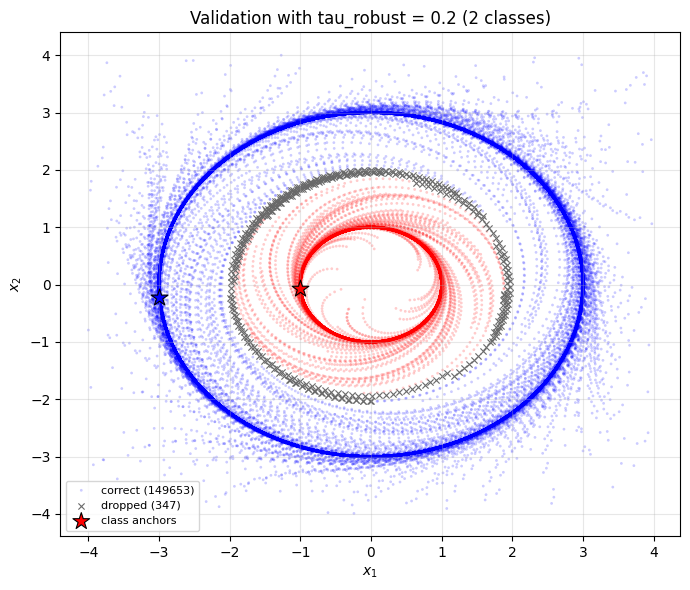

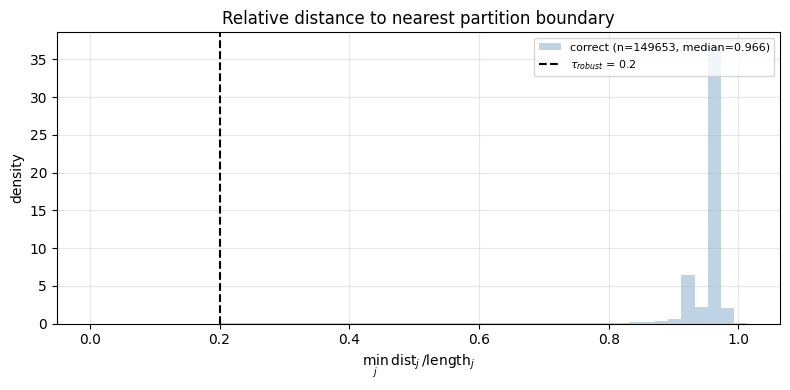

In [15]:
TAU_ROBUST = PAPER["tau_robust"] if PAPER["tau_robust"] > 0 else 0.05
result_final, inference_final = fit_partition(emb, tau_robust=TAU_ROBUST)
res_final = validate(emb, inference_final)
print(f"tau_robust = {TAU_ROBUST}")
print_classification_table(res_final.table_rows)

_ = plot_state_partition_2d(X, result_final["final_labels_X"],
                            title=f"Final partition with robustness margin (gray = dropped, {100 * np.mean(result_final['final_labels_X'] < 0):.1f}% of training points)")
_ = plot_misclassified_points(X_val, res_final.gt_labels, res_final.pred_mapped, anchors=res_final.anchors,
                              title=f"Validation with tau_robust = {TAU_ROBUST}")
rel_dist_final, _ = compute_relative_boundary_distances(emb["F_val"], inference_final)
misclassified_final = (res_final.pred_mapped >= 0) & (res_final.pred_mapped != res_final.gt_labels)
_ = plot_boundary_distance_histogram(rel_dist_final, misclassified_final, baseline_mask=res_final.correct_mask,
                                     tau_robust=TAU_ROBUST)

The margin removes a thin band around the boundary (gray in the state-space plot). Every remaining
misclassification, if any, lies just outside that band — the histogram's red bars start at
$\tau_{\mathrm{robust}}$ — and the classified points are scored at (or very near) 100%.

## Summary

| stage | parameter | what the sweep showed |
|---|---|---|
| GEP | $\gamma$ | too small: spurious near-zero eigenvalues from an ill-conditioned dictionary; too large: only the constant survives; pick the smallest $\gamma$ that gives $m$ modes below $\epsilon$ with a gap |
| fine cells | $k_j$ | must be `1` for the constant mode; parity and size of $k_2$ decide whether a fine cell straddles the boundary, which the merge steps then cannot undo |
| occupancy | $\tau_{\mathrm{occ}}$ | inactive at the paper $k_j$ (every cell is well populated), but **essential** as soon as the fine partition has thin cells: a single low-count cell that straddles the boundary transitions into both basins and collapses the partition unless $\tau_{\mathrm{occ}}$ removes it |
| transition merge | $\tau_{\mathrm{tr}}$ | collapse below a threshold, then a stationary plateau with the right number of cells, then no merging |
| value merge | $\tau_{\mathrm{val}}$ | secondary refinement; too large merges across the true boundary |
| margin | $\tau_{\mathrm{robust}}$ | trades a small dropped fraction for near-perfect accuracy on the rest |

**Learnings about $\tau_{\mathrm{occ}}$.** The occupancy filter is not a cosmetic clean-up of small
cells; it is a minimum-count guard on the denominator of the empirical transition probability
$p_{ab} = n_{ab} / n_a$. Whether it matters is decided by the fine partition, not by the system:
with few, well-populated cells (the paper's $k_j$) it does nothing, while with a fragmented fine
partition (large $k_j$, or several invariant modes) the thinnest cells are exactly the ones lying on
the boundary between basins, and each of them needs only a couple of stray transitions to exceed
$\tau_{\mathrm{tr}}$ in both directions. The right value sits just above the weight of those
straddling cells and well below the weight of genuine cells — a window that is wide for a sensible
$k_j$ and narrow for an excessive one — so $\tau_{\mathrm{occ}}$ should be tuned together with
$k_j$, and kept at a non-zero value as insurance even when the current settings do not need it.

The same experiment can be reproduced from the command line with
`python scripts/build_partition.py configs/<system>/build_partition.json` followed by
`python scripts/validate_partition.py configs/<system>/validate_partition.json`.

## 8. Regional EDMD models vs vanilla EDMD

With the partition fixed (`inference_final`: the config parameters plus the robustness margin), we now
build the prediction models of `scripts/build_multiple_linear_models.py`:

* **regional EDMD** — one regional EDMD model $(K_\ell, R_\ell)$ per partition cell, fitted on the snapshot
  pairs the partition assigns to that cell; pairs the partition drops (label $-1$, i.e. inside the
  $\tau_{\mathrm{robust}}$ band) are *excluded* from the fit;
* **vanilla EDMD** — a single global model $(K, R)$ fitted on *all* snapshot pairs with the *same*
  dictionary object (same RBF centers, same $\gamma$, same polynomial degree).

Both use the same dictionary $\Psi$ and are rolled out the same way: the initial condition is lifted
once, $z_0 = \Psi(x_0)$, the lifted state is propagated linearly, $z_{t+1} = z_t K$ (with $K = K_\ell$
for the cell of $x_0$ throughout: the cells are forward invariant, so the model is never regional), and $x_t = z_t R$ is decoded for storage only —
the decoded state is never re-lifted. This is the honest linear-Koopman rollout; it exposes how far
the span of $\Psi$ is from being $K$-invariant, which a chained one-step predictor would hide.

To keep this cheap we evaluate only on the initial conditions in `ICs_phase_plot`
(`run_gated_evaluation = false` in the config). The classification-gated evaluation on the full
validation set is what the script prints when that flag is `true`.

The true trajectories are produced by `SystemsAutonomous("bistable_oscillations")`
(`src_omega_partition/dynamical_systems.py`), which
reproduces the stored datasets to $\sim 10^{-7}$ (exact flow of $\dot r = (r-2) - (r-2)^3$,
$\dot\theta = 1$, sampled every $\Delta t = 0.05$). We test on **two initial conditions on opposite
sides of the unstable cycle $r = 2$**, chosen so that each has a genuine transient before settling:

* $x_0 = 1.5\,(\cos\tfrac{\pi}{4}, \sin\tfrac{\pi}{4}) \approx (1.061, 1.061)$ — converges to the inner cycle $r = 1$;
* $x_0 = 2.5\,(\cos(-\tfrac{2\pi}{3}), \sin(-\tfrac{2\pi}{3})) \approx (-1.25, -2.165)$ — converges to the outer cycle $r = 3$.

Both are correctly classified by the final partition (no robustness-margin drop). The four initial
conditions in the config (`ICs_phase_plot`) are the ones in the paper figure; they are overridden
below for this study only.

In [16]:
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
import build_multiple_linear_models as bmlm
from src_omega_partition.dictionary import sample_edmd_centers
from src_omega_partition.partition import classify_partition_labels
from src_omega_partition.regional_models import fit_regional_edmd_models, fit_vanilla_edmd_model

mlm_cfg = bmlm.load_settings(PROJECT_ROOT / f"configs/{SYSTEM}/build_multiple_linear_models.json")
mlm_cfg["run_gated_evaluation"] = False   # IC rollouts only; the gated validation-set evaluation takes minutes
mlm_cfg["ICs_phase_plot"] = [[1.5 * np.cos(np.pi / 4), 1.5 * np.sin(np.pi / 4)],
                             [2.5 * np.cos(-2 * np.pi / 3), 2.5 * np.sin(-2 * np.pi / 3)]]   # r0 = 1.5 -> r = 1, r0 = 2.5 -> r = 3
EDMD = {k: mlm_cfg[k] for k in ("edmd_gamma", "edmd_d_poly", "number_centers_edmd", "prediction_horizon",
                                "ICs_phase_plot", "rollout_rel_rmse_times")}
display(pd.Series({k: str(v) for k, v in EDMD.items()}, name="config value").to_frame())

fit_data = np.load(resolve(mlm_cfg["data_path"]))
X_fit, Y_fit = fit_data["X"], fit_data["Y"]
traj_fit = fit_data["trajectories"] if "trajectories" in fit_data else None
labels_fit = classify_partition_labels(X_fit, inference_final)
print(f"EDMD fit data: {mlm_cfg['data_path']} ({X_fit.shape[0]} pairs); "
      f"partition-dropped: {np.sum(labels_fit < 0)} ({100 * np.mean(labels_fit < 0):.2f}%) -> excluded from the regional fit only")

phase_true, horizon = bmlm._phase_plot_true_trajectories(traj_fit, mlm_cfg, n_state=n)
print(f"{phase_true.shape[0]} test trajectories of {horizon} steps from x0 = {[np.round(x, 3).tolist() for x in phase_true[:, 0]]}")


def build_edmd_models(gamma, d_poly, n_centers, *, partition=inference_final, labels=labels_fit):
    '''Regional EDMD per partition cell (dropped pairs excluded) + one vanilla EDMD on all pairs, same dictionary.
    n_centers = 0 gives a polynomial-only dictionary.'''
    centers = sample_edmd_centers(centers_global, n_centers, random_state=mlm_cfg["random_state"], verbose=False)
    Phi = build_rbf_polynomial_dictionary(n, centers, gamma, d_poly)
    regional = fit_regional_edmd_models(X_fit, Y_fit, labels, Phi, min_samples=mlm_cfg["min_samples_per_cell"])
    vanilla = fit_vanilla_edmd_model(X_fit, Y_fit, Phi)
    return Phi, regional, vanilla


def rollout_ics(Phi, regional, vanilla, *, partition=inference_final):
    '''Lift once, propagate in the lifted space, decode for storage (regional_koopman_rollout / vanilla_koopman_rollout).'''
    rgn = bmlm._rollouts_from_trajectories(phase_true, horizon, bmlm._regional_rollout_fn(regional, partition, Phi))
    van = bmlm._rollouts_from_trajectories(phase_true, horizon, bmlm._vanilla_rollout_fn(vanilla, Phi))
    return rgn, van, bmlm._metrics_from_rollouts(rgn, horizon, mlm_cfg), bmlm._metrics_from_rollouts(van, horizon, mlm_cfg)


def spectral_radius(K):
    return float(np.max(np.abs(np.linalg.eigvals(K))))


rng_onestep = np.random.default_rng(0)
onestep_idx = rng_onestep.choice(X_fit.shape[0], size=min(20000, X_fit.shape[0]), replace=False)

def onestep_state_rel_err(Phi, regional, vanilla):
    '''In-sample one-step relative state error on a 20k subsample of the fit pairs (regional: per-cell operator).'''
    Xs, Ys, ls = X_fit[onestep_idx], Y_fit[onestep_idx], labels_fit[onestep_idx]
    rgn = []
    for l, K in regional["K_by_label"].items():
        m = ls == l
        if m.any():
            rgn.append(bmlm._one_step_sample_errors(Xs[m], Ys[m], K, regional["R_by_label"][l], Phi)[2])
    van = bmlm._one_step_sample_errors(Xs, Ys, vanilla["K"], vanilla["R"], Phi)[2]
    return float(np.mean(np.concatenate(rgn))), float(np.mean(van))


def phase_portrait(rgn, van, title):
    '''State-space view: partition cells (light), true / regional / vanilla trajectories.'''
    if n != 2:
        return
    fig, ax = plt.subplots(figsize=(7, 6))
    scatter_cells(ax, labels_fit, title, X_plot=X_fit, s=2)
    for i, ((true, pred_reg, _), (_, pred_van, _)) in enumerate(zip(rgn, van)):
        ax.plot(true[:, 0], true[:, 1], color="black", lw=1.5, label="true" if i == 0 else None)
        ax.plot(pred_reg[:, 0], pred_reg[:, 1], color="crimson", lw=1.2, ls="--", label=bmlm.REGIONAL_LABEL if i == 0 else None)
        ax.plot(pred_van[:, 0], pred_van[:, 1], color="steelblue", lw=1.2, ls=":", label=bmlm.VANILLA_LABEL if i == 0 else None)
        ax.plot(true[0, 0], true[0, 1], "o", color="black", ms=6)
    lo, hi = np.nanmin(X_fit, axis=0), np.nanmax(X_fit, axis=0)
    pad = 0.15 * (hi - lo)
    ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

,config value
edmd_gamma,1.0
edmd_d_poly,6
number_centers_edmd,100
prediction_horizon,300
reclassify_each_step,False
ICs_phase_plot,"[[np.float64(1.0606601717798214), np.float64(1..."
rollout_rel_rmse_times,"[0, 50, 100, 200, 300]"


EDMD fit data: data/bistable_oscillations/bistable_oscillations_validation_data.npz (150000 pairs); partition-dropped: 347 (0.23%) -> excluded from the switched fit only

Phase plots: simulating 2 trajectory(s) from ICs_phase_plot
2 test trajectories of 300 steps from x0 = [[1.061, 1.061], [-1.25, -2.165]]


dictionary: 128 elements | switched models on 149653 pairs (cell 0: 121757, cell 1: 27896) | vanilla on 150000 pairs
spectral radius of K: {'cell 0': 1.00019, 'cell 1': 1.00034} | vanilla: 1.00029


in-sample one-step state rel. error: switched 2.335e-05 | vanilla 1.238e-04

Horizon = 300, 2 trajectories sampled, reclassify_each_step = False
+------------------------------+---------------+--------------+
| Metric                       | switched EDMD | vanilla EDMD |
+==============================+===============+==============+
| Valid rollouts               | 2             | 2            |
| Mean rollout RMSE            | 0.0191648     | 0.283901     |
| Max rollout RMSE             | 0.0212977     | 0.319547     |
| Dropped rollout steps (frac) | 0.0000        | 0.0000       |
+------------------------------+---------------+--------------+
+---------------------------------+---+-----------+-----------+------------+------------+
| Time step                       | 0 | 50        | 100       | 200        | 300        |
+=================================+===+===========+===========+============+============+
| Mean rel. error (switched EDMD) | 0 | 0.0191704 | 0.0128226 | 0.0087667

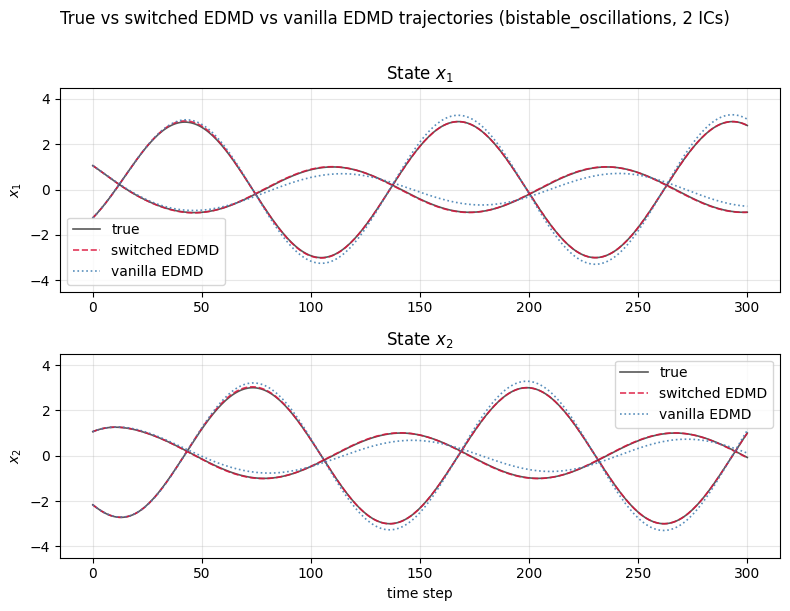

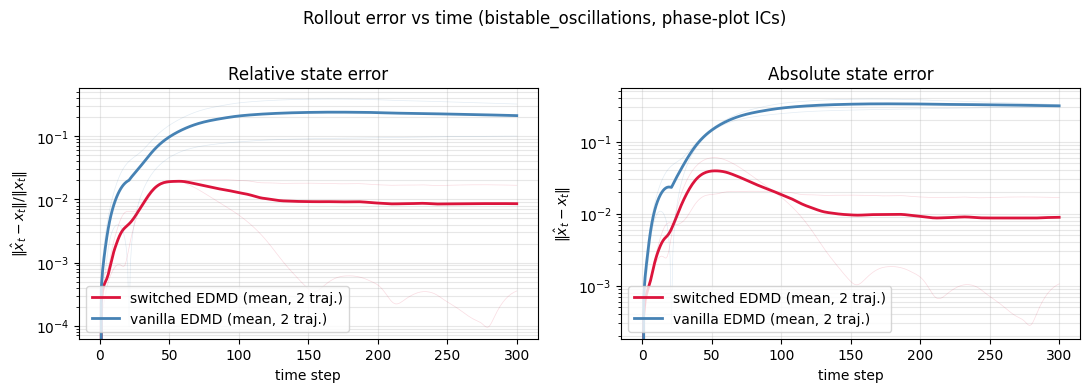

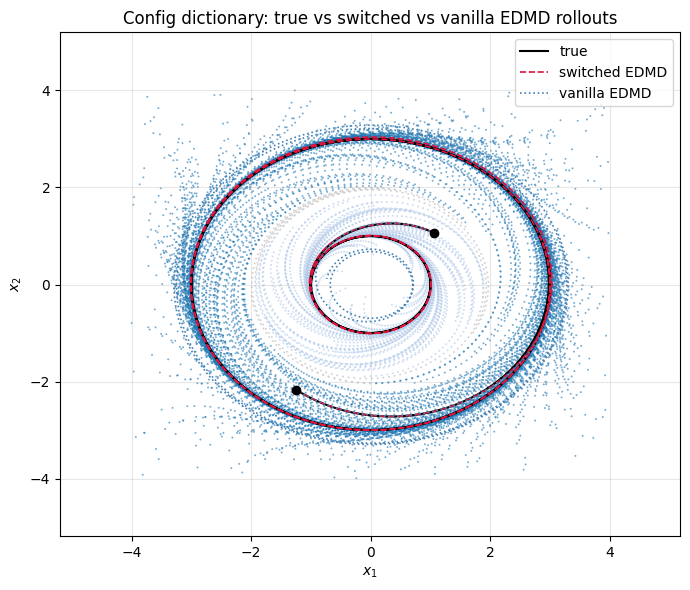

In [17]:
Phi_cfg, regional_cfg, vanilla_cfg = build_edmd_models(EDMD["edmd_gamma"], EDMD["edmd_d_poly"], EDMD["number_centers_edmd"])
print(f"dictionary: {Phi_cfg.s} elements | regional models on "
      f"{sum(regional_cfg['sample_counts'].values())} pairs ({', '.join(f'cell {l}: {c}' for l, c in sorted(regional_cfg['sample_counts'].items()))})"
      f" | vanilla on {vanilla_cfg['n_samples']} pairs")
print("spectral radius of K:", {f"cell {l}": round(spectral_radius(K), 5) for l, K in regional_cfg["K_by_label"].items()},
      "| vanilla:", round(spectral_radius(vanilla_cfg["K"]), 5))
one_reg, one_van = onestep_state_rel_err(Phi_cfg, regional_cfg, vanilla_cfg)
print(f"in-sample one-step state rel. error: regional {one_reg:.3e} | vanilla {one_van:.3e}")

reg_cfg, van_cfg, m_reg, m_van = rollout_ics(Phi_cfg, regional_cfg, vanilla_cfg)
print()
bmlm._print_rollout_summary(m_reg, m_van, gated=False)
bmlm._print_rollout_rel_rmse_times(m_reg, m_van)
_ = bmlm.plot_phase_trajectories(reg_cfg, mlm_cfg["system_name"], vanilla_rollouts=van_cfg, show=True)
_ = bmlm.plot_rollout_errors(m_reg["rel_err_curves"], m_reg["abs_err_curves"], rel_vanilla=m_van["rel_err_curves"],
                              abs_vanilla=m_van["abs_err_curves"], system_name=mlm_cfg["system_name"],
                              subtitle="phase-plot ICs", show=True)
phase_portrait(reg_cfg, van_cfg, "Config dictionary: true vs regional vs vanilla EDMD rollouts")

On a limit cycle the lifted linear model must carry a pair of eigenvalues on the unit circle,
$e^{\pm i\Delta t}$, to represent the rotation, so the rollout error is dominated by amplitude and
phase drift rather than by convergence to a point. The regional model has one cycle per cell and can
put its unit-circle pair at the right radius; the vanilla model must represent both cycles — and the
transients between $r = 1$ and $r = 3$ — with one operator. Section 9 varies the dictionary.

## 9. Effect of the EDMD dictionary (fixed partition)

Everything above the dictionary is now frozen — the partition `inference_final`, the fit data, the
lift-once rollout, the two initial conditions above ($r_0 = 1.5$ and $r_0 = 2.5$) — and only $\Psi$ changes. Three families:

1. **polynomial only** (`number_centers_edmd = 0`), degree $d = 1, \ldots, 6$;
2. **RBF + polynomial** grids: $n_c \in \{10, 30, 100\}$ centers subsampled from `centers_global`,
   precision $\gamma \in \{0.1, 1, 10\}$ (the code uses $e^{-\gamma\|x-c\|^2}$, so larger $\gamma$
   is *narrower*), degree $d \in \{1, 3, 6\}$.

For every dictionary we record the size $s$, the largest spectral radius $\rho(K_\ell)$ over the
regional operators and $\rho(K)$ of the vanilla one, the in-sample one-step state error, and the
rollout errors on the two initial conditions above ($r_0 = 1.5$ and $r_0 = 2.5$) (mean RMSE over the horizon, and the relative error at
the `rollout_rel_rmse_times`). The list is sorted by the regional rollout RMSE.

In [18]:
sweep_grid = [(0.0, d, 0) for d in (1, 2, 3, 4, 5, 6)]                         # polynomial only
sweep_grid += [(g, d, c) for c in (10, 30, 100) for g in (0.1, 1.0, 10.0) for d in (1, 3, 6)]

rows, curves = [], {}
t0 = time.time()
for gamma, d_poly, n_centers in sweep_grid:
    Phi, regional, vanilla = build_edmd_models(gamma, d_poly, n_centers)
    _, _, m_reg_i, m_van_i = rollout_ics(Phi, regional, vanilla)   # do not shadow m_reg / m_van of the config run
    one_reg, one_van = onestep_state_rel_err(Phi, regional, vanilla)
    key = (n_centers, gamma if n_centers else np.nan, d_poly)
    curves[key] = (m_reg_i["rel_err_curves"], m_van_i["rel_err_curves"])
    rows.append(dict(centers=key[0], gamma=key[1], d_poly=d_poly, s=Phi.s,
                     rho_reg=max(spectral_radius(K) for K in regional["K_by_label"].values()),
                     rho_van=spectral_radius(vanilla["K"]),
                     onestep_reg=one_reg, onestep_van=one_van,
                     reg_rmse=m_reg_i["mean_rmse"], van_rmse=m_van_i["mean_rmse"],
                     **{f"reg_rel@{t}": m_reg_i["rel_rmse_at_times"][t] for t in m_reg_i["rel_rmse_times"] if t > 0},
                     **{f"van_rel@{t}": m_van_i["rel_rmse_at_times"][t] for t in m_van_i["rel_rmse_times"] if t > 0}))
print(f"{len(rows)} dictionaries fitted and rolled out in {time.time() - t0:.0f}s")

table_dict = pd.DataFrame(rows).sort_values("reg_rmse").reset_index(drop=True)
fmt = {c: "{:.3g}" for c in table_dict.columns if c not in ("centers", "d_poly", "s")}
display(table_dict.style.format(fmt).background_gradient(subset=["reg_rmse", "van_rmse"], cmap="RdYlGn_r"))

33 dictionaries fitted and rolled out in 65s


,centers,gamma,d_poly,s,rho_sw,rho_van,onestep_sw,onestep_van,sw_rmse,van_rmse,sw_rel@50,sw_rel@100,sw_rel@200,sw_rel@300,van_rel@50,van_rel@100,van_rel@200,van_rel@300
0,100,1,6,128,1,1,2.34e-05,0.000124,0.0192,0.284,0.0192,0.0128,0.00877,0.00857,0.0981,0.211,0.238,0.214
1,10,0.1,6,38,1,1,9.76e-05,0.000778,0.0236,0.381,0.025,0.00498,0.00627,0.0099,0.304,0.304,0.254,0.208
2,100,1,3,110,1,1,3.35e-05,0.000151,0.0237,0.0651,0.0215,0.0181,0.0148,0.0156,0.0543,0.0385,0.046,0.0468
3,30,0.1,3,40,1,1,8.03e-05,0.000807,0.0256,0.354,0.0282,0.00917,0.0102,0.00591,0.301,0.294,0.238,0.183
4,100,1,1,103,1,1,0.000181,0.000382,0.0288,0.0642,0.0127,0.0159,0.0155,0.0158,0.0566,0.0426,0.0489,0.0426
5,30,0.1,1,33,1,1,0.000142,0.000815,0.0296,0.366,0.0221,0.011,0.0168,0.0236,0.294,0.288,0.238,0.191
6,30,1,6,58,1,1,0.000197,0.000752,0.0326,0.274,0.0306,0.0208,0.0145,0.0117,0.256,0.242,0.195,0.152
7,100,0.1,1,103,1,1,4.47e-05,0.000311,0.0381,0.335,0.0212,0.0153,0.0253,0.0463,0.243,0.247,0.179,0.126
8,30,0.1,6,58,1,1,4.55e-05,0.000512,0.0405,0.328,0.0241,0.0254,0.0308,0.0386,0.297,0.292,0.228,0.16
9,100,0.1,3,110,1,1,4.3e-05,0.00029,0.0462,0.328,0.0109,0.0446,0.0673,0.0623,0.236,0.23,0.192,0.155


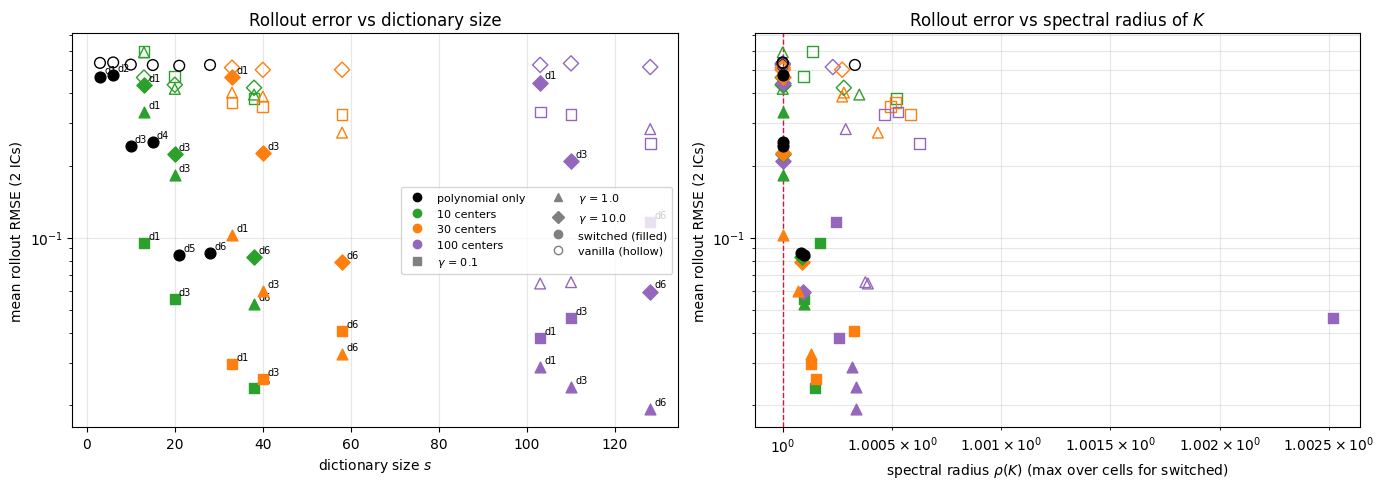

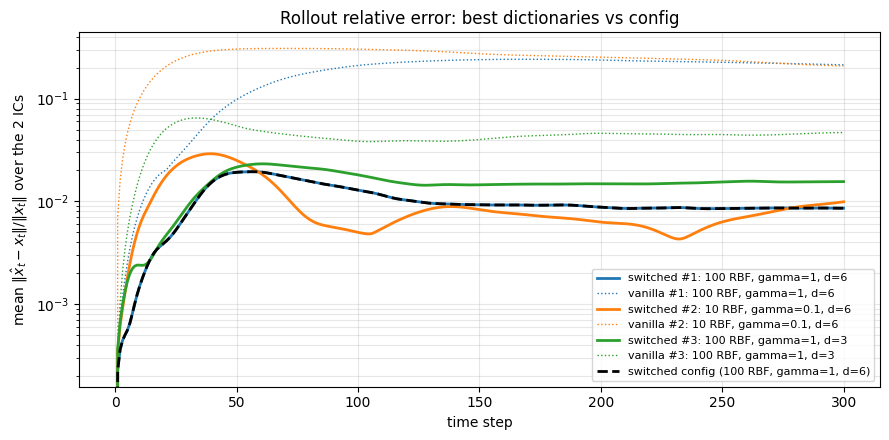

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fam_color = {0: "black", 10: "tab:green", 30: "tab:orange", 100: "tab:purple"}
gam_marker = {np.nan: "o", 0.1: "s", 1.0: "^", 10.0: "D"}
for _, r in table_dict.iterrows():
    mk = gam_marker[r["gamma"] if r["centers"] else np.nan]
    axes[0].scatter(r["s"], r["reg_rmse"], color=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
    axes[0].scatter(r["s"], r["van_rmse"], facecolors="none", edgecolors=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
    axes[0].annotate(f"d{int(r['d_poly'])}", (r["s"], r["reg_rmse"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    axes[1].scatter(r["rho_reg"], r["reg_rmse"], color=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
    axes[1].scatter(r["rho_van"], r["van_rmse"], facecolors="none", edgecolors=fam_color[r["centers"]], marker=mk, s=60, zorder=3)
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=c, marker="o", ls="", label=f"{k} centers" if k else "polynomial only") for k, c in fam_color.items()]
handles += [Line2D([], [], color="gray", marker=m, ls="", label=rf"$\gamma$ = {g}") for g, m in gam_marker.items() if g == g]
handles += [Line2D([], [], color="gray", marker="o", ls="", label="regional (filled)"),
            Line2D([], [], color="gray", marker="o", ls="", markerfacecolor="none", label="vanilla (hollow)")]
axes[0].set_xlabel("dictionary size $s$"); axes[0].set_ylabel("mean rollout RMSE (2 ICs)"); axes[0].set_yscale("log")
axes[0].set_title("Rollout error vs dictionary size"); axes[0].grid(alpha=0.3); axes[0].legend(handles=handles, fontsize=8, ncol=2)
axes[1].axvline(1.0, color="crimson", ls="--", lw=1)
axes[1].set_xlabel(r"spectral radius $\rho(K)$ (max over cells for regional)"); axes[1].set_ylabel("mean rollout RMSE (2 ICs)")
axes[1].set_yscale("log"); axes[1].set_xscale("log"); axes[1].set_title("Rollout error vs spectral radius of $K$"); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

# error curves of the best three regional dictionaries and of the config one
fig, ax = plt.subplots(figsize=(9, 4.5))
t = np.arange(horizon + 1)
for rank in range(3):
    r = table_dict.iloc[rank]
    key = (int(r["centers"]), r["gamma"] if r["centers"] else np.nan, int(r["d_poly"]))
    lab = f"#{rank + 1}: {'poly only' if not key[0] else f'{key[0]} RBF, gamma={key[1]:g}'}, d={key[2]}"
    with np.errstate(all="ignore"):
        ax.plot(t, np.nanmean(curves[key][0], axis=0), lw=2, label=f"regional {lab}")
        ax.plot(t, np.nanmean(curves[key][1], axis=0), lw=1, ls=":", color=ax.lines[-1].get_color(), label=f"vanilla {lab}")
with np.errstate(all="ignore"):
    ax.plot(t, np.nanmean(m_reg["rel_err_curves"], axis=0), lw=2, color="black", ls="--",
            label=f"regional config ({EDMD['number_centers_edmd']} RBF, gamma={EDMD['edmd_gamma']:g}, d={EDMD['edmd_d_poly']})")
ax.set_yscale("log"); ax.set_xlabel("time step"); ax.set_ylabel(r"mean $\|\hat{x}_t - x_t\| / \|x_t\|$ over the 2 ICs")
ax.set_title("Rollout relative error: best dictionaries vs config"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

best switched dictionary: centers = 100, gamma = 1.0, d_poly = 6  (s = 128)


+---------------------------------+---+-----------+-----------+------------+------------+
| Time step                       | 0 | 50        | 100       | 200        | 300        |
+=================================+===+===========+===========+============+============+
| Mean rel. error (switched EDMD) | 0 | 0.0191704 | 0.0128226 | 0.00876679 | 0.00857252 |
| Mean rel. error (vanilla EDMD)  | 0 | 0.0981132 | 0.210593  | 0.238072   | 0.213501   |
+---------------------------------+---+-----------+-----------+------------+------------+


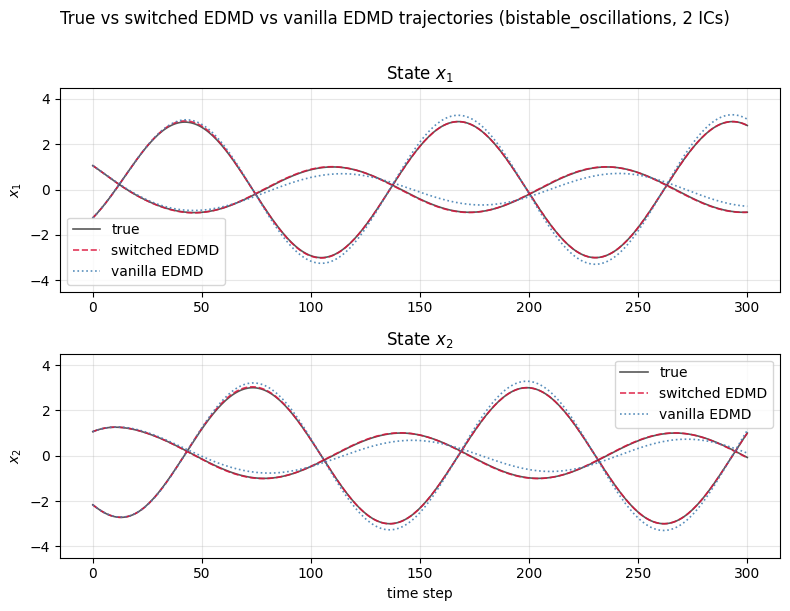

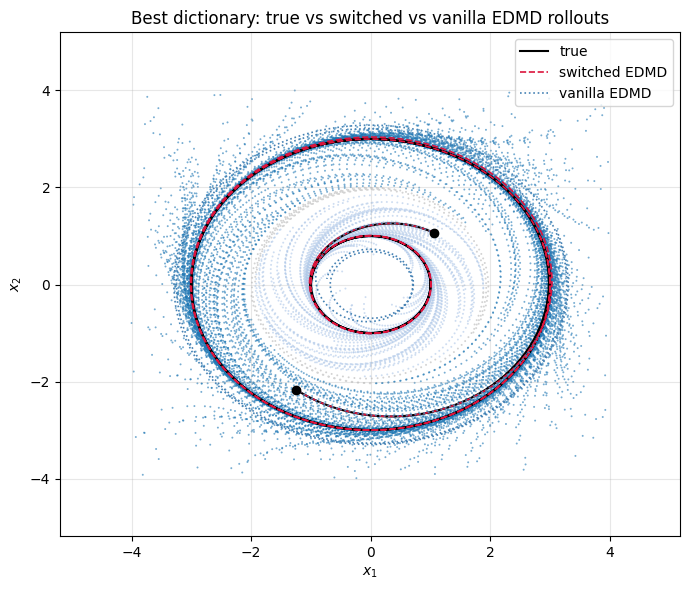

In [20]:
best = table_dict.iloc[0]
best_key = (int(best["centers"]), float(best["gamma"]) if best["centers"] else 0.0, int(best["d_poly"]))
print(f"best regional dictionary: centers = {best_key[0]}, gamma = {best_key[1]}, d_poly = {best_key[2]}  (s = {int(best['s'])})")
Phi_b, regional_b, vanilla_b = build_edmd_models(best_key[1], best_key[2], best_key[0])
reg_b, van_b, m_reg_b, m_van_b = rollout_ics(Phi_b, regional_b, vanilla_b)
bmlm._print_rollout_rel_rmse_times(m_reg_b, m_van_b)
_ = bmlm.plot_phase_trajectories(reg_b, mlm_cfg["system_name"], vanilla_rollouts=van_b, show=True)
phase_portrait(reg_b, van_b, "Best dictionary: true vs regional vs vanilla EDMD rollouts")

### What works best, and why

**Ranking.** As for Duffing, the regional model beats the vanilla one for every one of the 33
dictionaries. Sorted by regional rollout RMSE on the two initial conditions ($r_0 = 1.5 \to r = 1$,
$r_0 = 2.5 \to r = 3$, 300 steps):

| dictionary | $s$ | regional RMSE | regional rel. err at $t = 300$ | vanilla RMSE |
|---|---|---|---|---|
| **100 RBF, $\gamma = 1$, $d = 6$** | 128 | **0.019** | 0.009 | 0.284 |
| 10 RBF, $\gamma = 0.1$, $d = 6$ | 38 | 0.024 | 0.010 | 0.381 |
| 100 RBF, $\gamma = 1$, $d = 3$ | 110 | 0.024 | 0.016 | **0.065** |
| 30 RBF, $\gamma = 0.1$, $d = 3$ | 40 | 0.026 | **0.006** | 0.354 |
| 100 RBF, $\gamma = 1$, $d = 1$ | 103 | 0.029 | 0.016 | 0.064 |
| 30 RBF, $\gamma = 1$, $d = 6$ | 58 | 0.033 | 0.012 | 0.274 |
| polynomial only, $d = 5$–$6$ | 21–28 | 0.085 | 0.048 | 0.52 |
| **config** (10 RBF, $\gamma = 1$, $d = 3$) | 20 | 0.183 | 0.089 | 0.418 |
| any $\gamma = 10$ dictionary | 13–128 | 0.06–0.47 | 0.03–0.24 | 0.42–0.53 |

**What decides the order here.**

1. **The RBF width has to match the geometry, and the geometry is larger than Duffing's.** The
   data live in a disc of radius $\sim 4$ with cycles at $r = 1$ and $r = 3$; the relevant length
   scale is $\sim 1$–$3$. $\gamma = 1$ (width $\sim 1$) needs many centers to tile that disc — with
   100 it is the best family, with 10 it is the config, which is 8× worse. $\gamma = 0.1$ (width
   $\sim 3$) covers the disc with a handful of bumps: **10 wide RBFs + degree 6 ($s = 38$) are as
   good as 100 narrow ones + degree 6 ($s = 128$)**, and 30 wide RBFs + degree 3 ($s = 40$) has the
   lowest error at $t = 300$ of all. $\gamma = 10$ (width $\sim 0.3$) is bad everywhere: the bumps
   do not overlap, so between centers the dictionary is polynomial-only and the fit is patchy.
   For Duffing (basins of width $\sim 2$) the same reasoning favoured $\gamma = 1$ over $0.1$; the
   rule that carries over is *width $\approx$ size of the attractor features*, not a fixed $\gamma$.
2. **Polynomials alone cannot represent limit cycles.** Polynomial-only saturates at 0.085
   ($d = 5, 6$) and is 0.24–0.48 for $d \le 4$. The Koopman eigenfunctions of a limit cycle
   involve $e^{i\theta} = (x_1 + i x_2)/r$ and functions of $r = \sqrt{x_1^2 + x_2^2}$ — not
   polynomials in $x$ — and the radial dynamics $\dot r = (r-2) - (r-2)^3$ is cubic in $r$, not in
   $x$. The RBFs provide the radial structure; once they do, the polynomial degree matters little
   (100 RBF, $\gamma = 1$: $d = 1, 3, 6$ give 0.029, 0.024, 0.019).
3. **Wide RBFs and high polynomial degree should not be combined with many centers.** With
   $\gamma = 0.1$ the error gets *worse* with degree once there are enough centers (100 centers:
   $d = 1, 3, 6 \to 0.038, 0.046, 0.116$; 30 centers: $d = 3 \to 0.026$ but $d = 6 \to 0.041$).
   Wide bumps and high-order polynomials are both smooth, low-frequency functions on the disc, so
   the columns of $\Psi(X)$ become nearly collinear; the least-squares $K$ is then determined by the
   noise floor along those directions, and the lift-once rollout amplifies exactly that. The
   in-sample one-step error of that dictionary is excellent ($2.7 \times 10^{-5}$), so again the
   rollout, not the fit, is the right criterion.

**Why the regional model wins, and how it differs from Duffing.** Here *both* operators have
$\rho(K) = 1$ to machine precision — there is no growing mode in the vanilla model, unlike in the
Duffing case. What the vanilla model gets wrong is the *radius and phase* of the rotation: one
$K$ on a continuous span has to carry the unit-circle eigenvalue pair $e^{\pm i\Delta t}$ for both
cycles and the transients between them, and the least-squares compromise puts the predicted orbit
at the wrong amplitude (the phase portrait in Section 8 shows the vanilla orbit circling at a radius
between the two cycles). Its error therefore saturates at 0.2–0.5 from $t \approx 30$ on instead of
growing. The regional model has one cycle per cell, its $K_\ell$ places the rotation pair at the
right radius, and the error *decreases* after the transient ($t \gtrsim 50$) and settles at
$\sim 10^{-2}$; what remains is a slow phase drift, visible in the plots as a residual that no longer
decays. The one dictionary where the vanilla model is respectable (100 RBF, $\gamma = 1$, $d = 3$
or $1$: 0.065) is the one where the span is rich enough for a global $K$ to approximately separate
the two cycles by itself — and even there the regional model is 3× better.

**Recommendation.** Use `edmd_gamma = 1.0`, `number_centers_edmd = 100`, `edmd_d_poly = 3` (or 6)
for the paper — the same choice as for Duffing, and with $d = 3$ it also gives the strongest
vanilla baseline, which makes the comparison fairer. If the dictionary must stay small, `10`
centers with `gamma = 0.1` and `d_poly = 6` ($s = 38$) or `30` centers with `gamma = 0.1` and
`d_poly = 3` ($s = 40$) are within 25% of the best at a third of the size, and either is ~7× better
than the current config (`10`, `1.0`, `3`). Avoid `gamma = 10`, and avoid `d_poly = 6` together with
`gamma = 0.1` and many centers. As with Duffing, the ranking within the top group rests on two
initial conditions and should be confirmed with `run_gated_evaluation = true` (on validation
trajectories with correctly classified initial conditions) before the numbers go into Table I.